# Modul 7 — Ekstraksi Data: API, Web Scraping, dan ETL

**Praktikum Data Wrangling (SD25-20007) · Program Studi Sains Data ITERA**

Workbench menyimpan notebook ini di laptop sebagai **`dw-module-07/07_ekstraksi.ipynb`**; seluruh
keluaran modul juga ditulis ke folder `dw-module-07/` itu. Dataset tidak perlu diunduh: tekan
**Siapkan dataset di laptop** pada panel *Dataset di laptop* halaman modul (Local Runner menyala),
dan `data/raw/` terbentuk di akar workspace. Katalog produk Bagian C dibaca dari
`data/acuan/produk_m04.parquet`, keluaran acuan Modul 4 yang disediakan (bukan keluaran Modul 4 Anda
sendiri): unduh `data-acuan-modul-07.zip` di halaman modul dan ekstrak di folder `data-wrangling/`.
Buku ajar: Bab 8.2–8.4, 10.2.5, dan 10.5.

> **Satu berkas tambahan wajib.** Modul ini memakai server tiruan Lapak Sumatera,
> **`server_lapak.py`**. Workbench hanya menyalin notebook ke laptop; unduh `server_lapak.py` dari
> daftar *Berkas* halaman Modul 07 (tombol **Unduh**) dan letakkan di **`dw-module-07/`**, di
> samping notebook ini. Sel A.1 mencarinya di sana dan menjalankannya di thread latar kernel.

| Bagian | Isi notebook ini | Dinilai? |
|---|---|---|
| A–D Prosedur terbimbing | **kode lengkap dan pembahasan** | dijalankan dan lulus checkpoint |
| Latihan 7.1–7.2 | kerangka `TODO` | **ya** — *Latihan Mandiri di Lab* (20% nilai modul) |
| Tugas Individu | kerangka `TODO` | **ya** — *Tugas Individu* (80% nilai modul) |

Bagian A–D bukan untuk disalin tanpa dibaca. Latihan dan tugas memakai **cara berpikir yang
sama**: endpoint Anda sendiri, analisis etika, dan ETL inkremental terhadap keadaan data yang
berubah. Pertanyaan analisis menanyakan alasan di balik setiap langkah A–D.

**Aturan main**
1. `data/raw/` dan `data/acuan/` bersifat *read-only* — jangan pernah menulis ke sana.
2. `server_lapak.py` adalah sistem milik "pihak lain". Pelajari perilakunya dari respons, kode
   status, header, dan dokumentasi di `GET /`, bukan dengan menyunting berkasnya.
3. Setiap permintaan dicatat pada log permintaan; setiap keputusan dicatat pada
   `log-keputusan.csv` di akar workspace.
4. Tidak ada rekaman atau halaman yang hilang tanpa catatan.
5. Sebelum mengumpulkan: *Kernel → Restart Kernel and Run All Cells*, lalu jalankan Checkpoint.

## Bagian A — Mengonsumsi API dengan jujur

### A.1 Menyiapkan notebook dan menjalankan server

In [30]:
import os
import sys
import json
import time
import sqlite3
import hashlib
import importlib.util
import re
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urljoin, urlsplit
from urllib.robotparser import RobotFileParser

import numpy as np
import pandas as pd
import matplotlib

# Kernel DSWorkbench menjalankan sel di luar thread utama, sehingga backend GUI
# (mis. "macosx") gagal membuat figure. Di luar Jupyter/ipykernel dipakai Agg;
# figure yang terbuka tetap ditampilkan kernel sebagai gambar di bawah sel.
if "ipykernel" not in sys.modules:
    import warnings
    matplotlib.use("Agg")
    warnings.filterwarnings("ignore", message=r"FigureCanvas\w* is non-interactive")
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "raw").is_dir()), None)
if ROOT is None:   # dataset mentah belum disiapkan di laptop ini
    raise FileNotFoundError(
        "Folder data/raw/ (dataset mentah) belum ada di folder data-wrangling/. Di aplikasi "
        "DSWorkbench, nyalakan Local Runner lalu tekan Siapkan berkas modul pada modul ini; "
        "dataset disiapkan ke data/raw/. Setelah itu jalankan ulang sel ini.")
RAW = ROOT / "data" / "raw"
MODUL = ROOT / "dw-module-07"      # folder tempat Workbench menyimpan notebook ini
OUT = MODUL / "keluaran"
OUT.mkdir(parents=True, exist_ok=True)
LOG = ROOT / "log-keputusan.csv"
SEED = 2026
API_KEY = os.environ.get("LAPAK_API_KEY", "praktikum-dw")   # kunci sungguhan hanya dari variabel lingkungan
pd.set_option("display.width", 140)


def muat_server_lapak():
    """Cari server_lapak.py di folder modul (atau lokasi lain yang lazim), lalu impor."""
    calon = [MODUL / "server_lapak.py", Path.cwd() / "server_lapak.py", ROOT / "server_lapak.py",
             ROOT / "notebooks" / "module-07" / "server_lapak.py"]
    path = next((p for p in calon if p.is_file()), None)
    if path is None:
        raise FileNotFoundError(
            f"server_lapak.py tidak ditemukan. Unduh dari daftar Berkas halaman Modul 07, "
            f"letakkan di {MODUL.name}/ di samping notebook ini, lalu jalankan ulang sel ini.")
    spec = importlib.util.spec_from_file_location("server_lapak", path)
    modul = importlib.util.module_from_spec(spec)
    sys.modules["server_lapak"] = modul
    spec.loader.exec_module(modul)
    return modul, path


server_lapak, PATH_SERVER = muat_server_lapak()
if "SRV" in globals():
    SRV.stop()                     # aman dijalankan ulang: server lama dihentikan dulu
SRV = server_lapak.mulai_server(RAW / "produk.csv")
BASE = SRV.base_url
print("Akar repositori :", ROOT.name)
print("server_lapak.py :", PATH_SERVER.relative_to(ROOT))
print("server          :", BASE)
print(json.dumps(requests.get(BASE + "/", timeout=5).json(), indent=1, ensure_ascii=False)[:900])

Akar repositori : data-wrangling
server_lapak.py : dw-module-07\server_lapak.py
server          : http://127.0.0.1:55961
{
 "nama": "Lapak Sumatera Data API (tiruan untuk praktikum)",
 "edisi": 1,
 "data_per": "2026-07-01T00:00:00Z",
 "autentikasi": "header X-API-Key pada setiap permintaan /api/",
 "pembatasan_laju": "5 permintaan per detik per klien; melebihi batas dijawab 429 dengan header Retry-After (detik)",
 "endpoint": [
  {
   "path": "/api/v1/toko",
   "parameter": {
    "page": "mulai 1",
    "per_page": "bawaan 20, maksimal 50"
   },
   "respons": "data, page, per_page, total, next"
  },
  {
   "path": "/api/v1/toko/<id_toko>",
   "respons": "satu toko"
  },
  {
   "path": "/api/v2/toko",
   "parameter": {
    "page": "mulai 1",
    "per_page": "bawaan 20, maksimal 50",
    "updated_since": "opsional, ISO 8601 UTC, misalnya 2026-06-30T00:00:00Z; hanya toko dengan updated_at sesudah waktu itu"
   },
   "respons": "items, meta, links"
  },
  {
   "path": "/situs/",
   "keteran

### A.2 Klien yang mencatat setiap permintaan

In [31]:
class Klien:
    """Klien HTTP yang sopan: jeda minimum, percobaan ulang terbatas, dan log setiap percobaan."""

    def __init__(self, base: str, api_key: str | None = None, jeda: float = 0.25,
                 maks_percobaan: int = 5, sumber: str = "api"):
        self.base, self.jeda, self.maks = base, jeda, maks_percobaan
        self.sumber = sumber
        self.sesi = requests.Session()
        self.sesi.trust_env = False            # server lokal: abaikan proxy sistem
        self.sesi.headers["User-Agent"] = "praktikum-dw-itera/2026 (tugas kuliah; kontak: asisten)"
        if api_key:
            self.sesi.headers["X-API-Key"] = api_key
        self.log: list[dict] = []
        self._terakhir = 0.0

    def _tunggu(self, detik: float) -> None:
        sisa = self._terakhir + detik - time.monotonic()
        if sisa > 0:
            time.sleep(sisa)

    def get(self, path: str, sumber: str | None = None) -> requests.Response:
        """GET dengan percobaan ulang untuk 429 dan 5xx; galat lain dikembalikan apa adanya."""
        url = urljoin(self.base, path)
        tunggu_lagi = self.jeda
        for ke in range(1, self.maks + 1):
            self._tunggu(tunggu_lagi)
            mulai = time.monotonic()
            try:
                r = self.sesi.get(url, timeout=10)
                status, ket = r.status_code, ""
            except requests.RequestException as e:   # koneksi putus, waktu habis
                r, status, ket = None, None, type(e).__name__
            self._terakhir = time.monotonic()
            if r is not None and status == 429:
                tunggu_lagi = float(r.headers.get("Retry-After", 1))
                ket = f"Retry-After {tunggu_lagi:g} s"
            elif r is None or status >= 500:
                tunggu_lagi = 0.5 * 2 ** (ke - 1)     # backoff eksponensial: 0,5; 1; 2; 4 s
                ket = (ket + f" backoff {tunggu_lagi:g} s").strip()
            self.log.append({
                "waktu": datetime.now().isoformat(timespec="milliseconds"),
                "sumber": sumber or self.sumber, "metode": "GET",
                "url": urlsplit(url).path + (f"?{urlsplit(url).query}" if urlsplit(url).query else ""),
                "status": status, "percobaan": ke,
                "durasi_ms": round(1000 * (self._terakhir - mulai), 1), "keterangan": ket,
            })
            if r is not None and status != 429 and status < 500:
                return r
            if ke == self.maks:
                raise RuntimeError(f"{url}: gagal setelah {ke} percobaan (status terakhir {status})")
        raise AssertionError("tidak tercapai")


# Uji batas laju dengan requests biasa: delapan permintaan secepat mungkin.
ledakan = [requests.get(BASE + "/api/v1/toko/T001", headers={"X-API-Key": API_KEY}, timeout=5)
           for _ in range(8)]
print("status:", [x.status_code for x in ledakan], "| Retry-After:", ledakan[-1].headers.get("Retry-After"))
print("tanpa kunci:", requests.get(BASE + "/api/v1/toko", timeout=5).status_code,
      "| kunci salah:", requests.get(BASE + "/api/v1/toko", headers={"X-API-Key": "x"}, timeout=5).status_code)
time.sleep(1)

api = Klien(BASE, API_KEY, sumber="api_v1")
r = api.get("/api/v1/toko?page=1&per_page=20")
print(r.status_code, {k: r.json()[k] for k in ["page", "per_page", "total", "next"]})
r.json()["data"][:2]

status: [200, 200, 200, 200, 200, 429, 429, 429] | Retry-After: 1
tanpa kunci: 401 | kunci salah: 403
200 {'page': 1, 'per_page': 20, 'total': 177, 'next': '/api/v1/toko?page=2&per_page=20'}


[{'id_toko': 'T001', 'nama_toko': 'Toko 001', 'provinsi': 'Lampung', 'kota': 'Bandar Lampung', 'rating': 3.7, 'jumlah_ulasan': 330, 'status': 'aktif', 'tanggal_bergabung': '2024-10-30'}, {'id_toko': 'T002', 'nama_toko': 'Toko 002', 'provinsi': 'Sumatera Barat', 'kota': 'Padang', 'rating': 4.0, 'jumlah_ulasan': 108, 'status': 'aktif', 'tanggal_bergabung': '2025-12-07'}]

### A.3 Pagination: cara buku dan cara yang jujur

In [32]:
def ambil_semua_naif(base_url, endpoint, api_key, per_page=20):
    """Pola buku ajar (Bab 8.2.2): berhenti pada respons pertama yang bukan 200."""
    semua, page = [], 1
    while True:
        r = requests.get(f"{base_url}{endpoint}", params={"page": page, "per_page": per_page},
                         headers={"X-API-Key": api_key}, timeout=10)
        if r.status_code != 200:
            print(f"Error on page {page}: {r.status_code}")
            break
        data = r.json()["data"]
        if not data:
            break
        semua.extend(data)
        if len(data) < per_page:
            break
        page += 1
    return semua


naif = ambil_semua_naif(BASE, "/api/v1/toko", API_KEY)
print(f"cara naif: {len(naif)} rekaman, padahal total = {r.json()['total']}")

Error on page 3: 500
cara naif: 40 rekaman, padahal total = 177


In [33]:
def ambil_semua(klien: Klien, path: str, kunci_data: str = "data") -> tuple[list, dict]:
    """Ikuti tautan `next` sampai habis; setiap halaman lewat klien yang mencoba ulang."""
    semua, halaman, berikut = [], 0, path
    while berikut:
        isi = klien.get(berikut).json()
        semua.extend(isi[kunci_data])
        halaman += 1
        berikut = isi["next"] if "next" in isi else isi["links"]["next"]
        total = isi["total"] if "total" in isi else isi["meta"]["total"]
    return semua, {"halaman": halaman, "total": total}


time.sleep(1)                       # jendela pembatas laju dari sel sebelumnya dikosongkan
rekam_v1, info_v1 = ambil_semua(api, "/api/v1/toko?page=1&per_page=20")
print(f"cara jujur: {len(rekam_v1)} rekaman dari {info_v1['halaman']} halaman; total = {info_v1['total']}")
log_api = pd.DataFrame(api.log)
print(log_api.status.value_counts(dropna=False).to_string())
log_api[log_api.status.ne(200)]

cara jujur: 177 rekaman dari 9 halaman; total = 177
status
200    10
500     1


,waktu,sumber,metode,url,status,percobaan,durasi_ms,keterangan
3,2026-11-11T15:35:41.860,api_v1,GET,/api/v1/toko?page=3&per_page=20,500,1,2.3,backoff 0.5 s


**Pembahasan A.3**

- Uji batas laju: delapan permintaan beruntun → `[200 × 5, 429 × 3]`, `Retry-After: 1`. Tanpa
  kunci 401, kunci salah 403.
- Pola buku berhenti di **halaman 3** dengan galat 500 dan mengembalikan **40 rekaman** tanpa
  galat Python apa pun. Notebook "berhasil", datanya terpotong 77%.
- Klien yang mencoba ulang mendapat 500 sekali lagi pada halaman 3 (server gagal dua kali
  pertama per versi; satu sudah "terpakai" oleh cara naif), berhasil pada percobaan ke-2,
  lalu mengikuti `next` sampai `null`: **177 rekaman dari 9 halaman**, sama dengan `total`.
- `total = 177` **sama dengan jumlah toko di katalog**. Kebetulan itu menggoda untuk berhenti
  memeriksa; A.4 dan C menunjukkan isinya berbeda.

### A.4 Validasi skema dan perbandingan v1–v2

In [34]:
SKEMA_V1 = {"id_toko": str, "nama_toko": str, "provinsi": str, "kota": str,
            "rating": (float, int, type(None)), "jumlah_ulasan": int, "status": str,
            "tanggal_bergabung": str}


def validasi(rekam: list[dict], skema: dict, kunci: str) -> pd.DataFrame:
    """Satu baris per masalah: field hilang, field asing, tipe salah, kunci ganda."""
    masalah, terlihat = [], {}
    for i, r in enumerate(rekam):
        id_ = r.get(kunci)
        for f, tipe in skema.items():
            if f not in r:
                masalah.append({"posisi": i, "id_toko": id_, "kolom": f, "nilai": None,
                                "masalah": "field hilang"})
            elif not isinstance(r[f], tipe) or isinstance(r[f], bool):
                masalah.append({"posisi": i, "id_toko": id_, "kolom": f, "nilai": repr(r[f]),
                                "masalah": f"tipe {type(r[f]).__name__}"})
        for f in set(r) - set(skema):
            masalah.append({"posisi": i, "id_toko": id_, "kolom": f, "nilai": repr(r[f]),
                            "masalah": "field asing"})
        if id_ in terlihat:
            sama = r == rekam[terlihat[id_]]
            masalah.append({"posisi": i, "id_toko": id_, "kolom": kunci, "nilai": id_,
                            "masalah": "kunci ganda (identik)" if sama else "kunci ganda (berbeda)"})
        terlihat.setdefault(id_, i)
    return pd.DataFrame(masalah, columns=["posisi", "id_toko", "kolom", "nilai", "masalah"])


masalah_v1 = validasi(rekam_v1, SKEMA_V1, "id_toko")
masalah_v1

,posisi,id_toko,kolom,nilai,masalah
0,21,T022,rating,"'4,2'",tipe str
1,37,T038,rating,"'4,5'",tipe str
2,47,T047,id_toko,T047,kunci ganda (identik)
3,102,T103,rating,"'4,2'",tipe str


In [35]:
api2 = Klien(BASE, API_KEY, sumber="api_v2")
time.sleep(1)
rekam_v2, info_v2 = ambil_semua(api2, "/api/v2/toko?page=1&per_page=50", kunci_data="items")
print(f"v2: {len(rekam_v2)} rekaman dari {info_v2['halaman']} halaman; total = {info_v2['total']}")
print("contoh v2:", json.dumps(rekam_v2[0], ensure_ascii=False))


def ratakan_v2(item: dict) -> dict:
    """Petakan field v2 ke nama kolom v1 (+ updated_at)."""
    return {"id_toko": item["kode_toko"], "nama_toko": item["nama"],
            "provinsi": item["wilayah"]["provinsi"], "kota": item["wilayah"]["kota"],
            "rating": item["ulasan"]["rating_rata"], "jumlah_ulasan": item["ulasan"]["jumlah"],
            "status": item["status"], "tanggal_bergabung": item["bergabung"],
            "updated_at": item["updated_at"]}


v2 = pd.DataFrame([ratakan_v2(x) for x in rekam_v2])
v1 = pd.DataFrame(rekam_v1)
print("v1 baris / id unik:", len(v1), "/", v1.id_toko.nunique(), "| v2 baris / id unik:", len(v2), "/", v2.id_toko.nunique())
print("id sama di kedua versi:", set(v1.id_toko) == set(v2.id_toko))

# bandingkan nilai per kolom, setelah duplikat identik v1 dibuang
v1u = v1.drop_duplicates()
gabung = v1u.merge(v2, on="id_toko", suffixes=("_v1", "_v2"))
for k in ["nama_toko", "provinsi", "kota", "jumlah_ulasan", "status", "tanggal_bergabung", "rating"]:
    x, y = gabung[f"{k}_v1"], gabung[f"{k}_v2"]
    beda = ~((x.astype(str) == y.astype(str)) | (x.isna() & y.isna()))
    print(f"{k:<18} berbeda: {int(beda.sum())}", gabung.loc[beda, ["id_toko", f"{k}_v1", f"{k}_v2"]].values.tolist()[:4])

v2: 176 rekaman dari 4 halaman; total = 176
contoh v2: {"kode_toko": "T001", "nama": "Toko 001", "wilayah": {"provinsi": "Lampung", "kota": "Bandar Lampung"}, "ulasan": {"rating_rata": 3.7, "jumlah": 330}, "status": "aktif", "bergabung": "2024-10-30", "updated_at": "2026-04-08T13:53:36Z"}
v1 baris / id unik: 177 / 176 | v2 baris / id unik: 176 / 176
id sama di kedua versi: True
nama_toko          berbeda: 0 []
provinsi           berbeda: 0 []
kota               berbeda: 0 []
jumlah_ulasan      berbeda: 0 []
status             berbeda: 0 []
tanggal_bergabung  berbeda: 0 []
rating             berbeda: 3 [['T022', '4,2', 4.2], ['T038', '4,5', 4.5], ['T103', '4,2', 4.2]]


In [36]:
# Keputusan validasi: rating teks berkoma dikonversi (dibuktikan oleh v2), duplikat identik dibuang.
def rating_ke_float(x):
    if isinstance(x, str):
        return float(x.replace(",", "."))
    return x


v1_bersih = v1u.assign(rating=v1u.rating.map(rating_ke_float))
cocok_v2 = v1_bersih.merge(v2, on="id_toko").pipe(
    lambda m: np.isclose(m.rating_x.astype(float), m.rating_y.astype(float), equal_nan=True).all())
print("rating v1 setelah konversi = rating v2:", cocok_v2)
naif_coerce = pd.to_numeric(v1u.rating, errors="coerce")
print("bila to_numeric(errors='coerce') dipakai:", int(naif_coerce.isna().sum() - v1u.rating.isna().sum()),
      "rating lenyap menjadi NaN tanpa pesan")

validasi_api = masalah_v1.assign(
    tindakan=np.where(masalah_v1.masalah.str.startswith("kunci ganda"), "dibuang (salinan identik)",
                      np.where(masalah_v1.kolom.eq("rating"), "dikonversi: koma -> titik, cocok dengan v2",
                               "ditinjau")))
validasi_api.to_csv(OUT / "validasi_api_m07.csv", index=False)


def simpan_log_permintaan(*klien: Klien) -> pd.DataFrame:
    """Gabungkan log semua klien, urut menurut waktu, simpan ke keluaran/etl_log_m07.csv."""
    lg = pd.DataFrame([x for k in klien for x in k.log]).sort_values("waktu", kind="stable")
    lg.to_csv(OUT / "etl_log_m07.csv", index=False)
    return lg


log_req = simpan_log_permintaan(api, api2)
validasi_api

rating v1 setelah konversi = rating v2: True
bila to_numeric(errors='coerce') dipakai: 3 rating lenyap menjadi NaN tanpa pesan


,posisi,id_toko,kolom,nilai,masalah,tindakan
0,21,T022,rating,"'4,2'",tipe str,"dikonversi: koma -> titik, cocok dengan v2"
1,37,T038,rating,"'4,5'",tipe str,"dikonversi: koma -> titik, cocok dengan v2"
2,47,T047,id_toko,T047,kunci ganda (identik),dibuang (salinan identik)
3,102,T103,rating,"'4,2'",tipe str,"dikonversi: koma -> titik, cocok dengan v2"


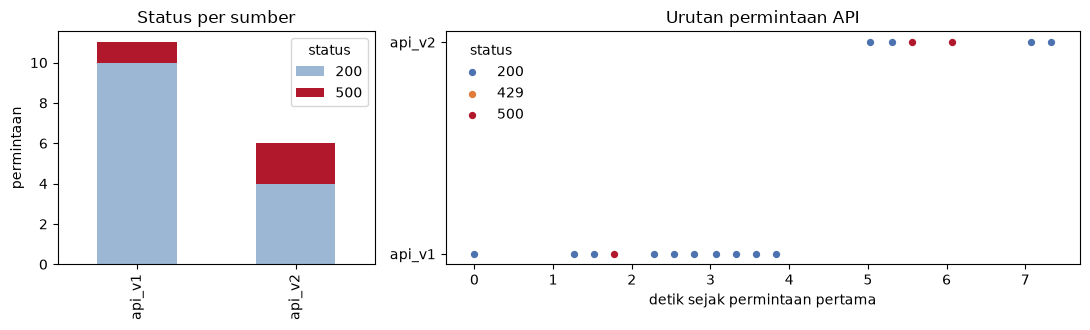

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2]})
hit = log_req.assign(status=log_req.status.astype("Int64").astype(str)).groupby(["sumber", "status"]).size().unstack(fill_value=0)
hit.plot(kind="bar", stacked=True, ax=ax1, color={"200": "#9bb7d4", "429": "#e07b39", "500": "#b2182b"})
ax1.set_xlabel(""); ax1.set_ylabel("permintaan"); ax1.set_title("Status per sumber")
t0 = pd.to_datetime(log_req.waktu).min()
for st, warna in [("200", "#4c72b0"), ("429", "#e07b39"), ("500", "#b2182b")]:
    m = log_req.status.astype("Int64").astype(str).eq(st)
    ax2.scatter((pd.to_datetime(log_req.waktu[m]) - t0).dt.total_seconds(), log_req.sumber[m],
                s=18, color=warna, label=st)
ax2.set_xlabel("detik sejak permintaan pertama"); ax2.legend(title="status", frameon=False)
ax2.set_title("Urutan permintaan API")
fig.tight_layout()
fig.savefig(OUT / "01_permintaan_api.png", dpi=110, bbox_inches="tight")
plt.show()

**Pembahasan A.4**

| Pemeriksaan | v1 | v2 |
|---|---:|---:|
| rekaman / id unik | 177 / **176** | 176 / 176 |
| masalah skema | 3 × `rating` bertipe `str` (`T022` `"4,2"`, `T038` `"4,5"`, `T103` `"4,2"`) + 1 kunci ganda identik (`T047`) | 0 |
| halaman 3 | 500 lalu 200 | 500, 500, lalu 200 |

- Kunci ganda: `T047` muncul dua kali berurutan (posisi 47–48). Salinannya identik sehingga
  aman dibuang; `total` ikut menghitungnya.
- Tiga rating berupa teks berkoma. Konversi koma → titik **dibuktikan** oleh v2: setelah
  dikonversi, seluruh 176 rating v1 sama dengan v2. `to_numeric(errors="coerce")` mengubah
  ketiganya menjadi NaN tanpa pesan (bersama kunci ganda).
- v2 mengganti nama field (`kode_toko`, `nama`, `wilayah.provinsi`, `ulasan.rating_rata`, …),
  membungkus data di `items`/`meta`/`links`, dan menambah `updated_at`; isinya sama dengan v1.
  Tiga toko tanpa rating (`T035`, `T092`, `T146`) bernilai `null` di kedua versi: kosong yang sah.

## Bagian B — Scraping yang etis dan tangguh

### B.1 robots.txt dan jeda

In [38]:
situs = Klien(BASE, sumber="situs")
teks_robots = situs.get("/situs/robots.txt", sumber="robots").text
print(teks_robots)
rp = RobotFileParser()
rp.parse(teks_robots.splitlines())
laju = rp.request_rate("*")
situs.jeda = max(0.25, laju.seconds / laju.requests) if laju else 1.0
print("jeda antarpermintaan:", situs.jeda, "detik")
for p in ["/situs/", "/situs/toko/T001.html", "/situs/pemilik/T001.html"]:
    print(f"{p:<28} boleh diambil: {rp.can_fetch(situs.sesi.headers['User-Agent'], BASE + p)}")

# Situs Lapak Sumatera (tiruan untuk praktikum Data Wrangling)
User-agent: *
Disallow: /situs/pemilik/
Request-rate: 5/1

jeda antarpermintaan: 0.25 detik
/situs/                      boleh diambil: True
/situs/toko/T001.html        boleh diambil: True
/situs/pemilik/T001.html     boleh diambil: False


### B.2 Direktori toko: mengikuti halaman berikutnya, menyaring jalur terlarang

In [39]:
tautan, berikut, n_dir = [], "/situs/", 0
while berikut:
    url_dir = urljoin(BASE, berikut)
    sup = BeautifulSoup(situs.get(url_dir).text, "lxml")
    n_dir += 1
    tautan += [urljoin(url_dir, a["href"]) for a in sup.select("ul.direktori a[href]")]
    nxt = sup.select_one("li.next a[href]")
    berikut = urljoin(url_dir, nxt["href"]) if nxt else None

boleh = [u for u in tautan if rp.can_fetch(situs.sesi.headers["User-Agent"], u)]
terlarang = [u for u in tautan if u not in boleh]
print(f"{n_dir} halaman direktori, {len(tautan)} tautan; boleh {len(boleh)}, dilarang robots.txt {len(terlarang)}")
print("contoh dilarang:", urlsplit(terlarang[0]).path)
url_profil = sorted(u for u in boleh if "/situs/toko/" in u)
print("profil toko yang akan diambil:", len(url_profil))

4 halaman direktori, 354 tautan; boleh 177, dilarang robots.txt 177
contoh dilarang: /situs/pemilik/T001.html
profil toko yang akan diambil: 177


### B.3 Mengurai profil dan etalase dengan selektor yang tangguh

In [40]:
SEBUTAN = {"NAD": "Aceh", "Sumut": "Sumatera Utara", "Sumbar": "Sumatera Barat",
           "Sumsel": "Sumatera Selatan", "Babel": "Kepulauan Bangka Belitung",
           "Kepri": "Kepulauan Riau"}


def harga_ke_int(teks: str | None) -> int | None:
    """'Rp128.000', 'Rp 128.000', 'Rp128.000,-', 'Rp 128rb' -> 128000; lainnya None."""
    if not teks:
        return None
    t = teks.replace("\xa0", " ").strip()
    m = re.fullmatch(r"Rp\s?(\d+)rb", t)
    if m:
        return int(m.group(1)) * 1000
    m = re.fullmatch(r"Rp\s?([\d.]+)(,-)?", t)
    if m and re.fullmatch(r"\d{1,3}(\.\d{3})*", m.group(1)):
        return int(m.group(1).replace(".", ""))
    return None


def teks_atau_none(induk, selektor: str) -> str | None:
    el = induk.select_one(selektor)
    return el.get_text(" ", strip=True) if el else None


def urai_baru(sup: BeautifulSoup, url: str) -> tuple[dict, list[dict]]:
    """Templat profil saat ini. Elemen yang hilang menjadi None, bukan galat."""
    art = sup.select_one("article.profil-toko") or sup
    tid = Path(urlsplit(url).path).stem
    nilai = teks_atau_none(art, "p.rating .nilai")
    jumlah = teks_atau_none(art, "p.rating .jumlah")
    toko = {"id_toko": tid, "nama_toko": teks_atau_none(art, "h1.nama-toko"),
            "provinsi": teks_atau_none(art, "p.lokasi .provinsi"),
            "kota": teks_atau_none(art, "p.lokasi .kota"),
            "rating": float(nilai.replace(",", ".")) if nilai else None,
            "jumlah_ulasan": int(re.sub(r"\D", "", jumlah)) if jumlah else None,
            "markup": "baru", "url": urlsplit(url).path}
    produk = []
    for li in sup.select("ul.daftar-produk li.produk"):
        harga_teks = teks_atau_none(li, ".harga")
        promo, coret = li.select_one(".harga-promo"), li.select_one(".harga-coret")
        stok = teks_atau_none(li, ".stok") or ""
        produk.append({"id_toko": tid, "kode_produk": li.get("data-kode"),
                       "nama_produk": teks_atau_none(li, ".nama-produk"), "harga_teks": harga_teks,
                       "harga_tayang_rp": harga_ke_int(promo.get_text(strip=True) if promo else harga_teks),
                       "harga_coret_rp": harga_ke_int(coret.get_text(strip=True)) if coret else None,
                       "stok": int(re.sub(r"\D", "", stok)) if re.search(r"\d", stok) else 0,
                       "markup": "baru"})
    return toko, produk


def urai_lama(sup: BeautifulSoup, url: str) -> tuple[dict, list[dict]]:
    """Templat lama: div#toko, teks 'Provinsi: X | Rating: 4.1/5 | Ulasan: n', tabel produk."""
    kotak = sup.select_one("div#toko")
    tid = Path(urlsplit(url).path).stem
    info = dict(bagian.split(":", 1) for bagian in kotak.select_one("div.info").get_text().split("|"))
    info = {k.strip(): v.strip() for k, v in info.items()}
    prov = info.get("Provinsi")
    toko = {"id_toko": tid, "nama_toko": teks_atau_none(kotak, "h2"),
            "provinsi": SEBUTAN.get(prov, prov), "kota": None,
            "rating": float(info["Rating"].split("/")[0]) if "Rating" in info else None,
            "jumlah_ulasan": int(info["Ulasan"]) if "Ulasan" in info else None,
            "markup": "lama", "url": urlsplit(url).path}
    produk = []
    for tr in kotak.select("table.tbl-produk tr")[1:]:
        kode, nama, harga = [td.get_text(strip=True) for td in tr.find_all("td")]
        produk.append({"id_toko": tid, "kode_produk": kode, "nama_produk": nama, "harga_teks": harga,
                       "harga_tayang_rp": harga_ke_int(harga), "harga_coret_rp": None,
                       "stok": None, "markup": "lama"})
    return toko, produk

In [41]:
toko_web_rek, produk_web_rek, gagal = [], [], []
for url in url_profil:
    r = situs.get(url)
    if r.status_code != 200:
        gagal.append({"url": urlsplit(url).path, "status": r.status_code, "alasan": "halaman tidak ada"})
        continue
    sup = BeautifulSoup(r.text, "lxml")
    if sup.select_one("article.profil-toko"):
        t, p = urai_baru(sup, url)
    elif sup.select_one("div#toko"):
        t, p = urai_lama(sup, url)
    else:
        gagal.append({"url": urlsplit(url).path, "status": r.status_code, "alasan": "markup tidak dikenal"})
        continue
    toko_web_rek.append(t)
    produk_web_rek += p

toko_web = pd.DataFrame(toko_web_rek)
produk_web = pd.DataFrame(produk_web_rek).astype({"harga_tayang_rp": "Int64", "harga_coret_rp": "Int64", "stok": "Int64"})
halaman_gagal = pd.DataFrame(gagal, columns=["url", "status", "alasan"])
halaman_gagal.to_csv(OUT / "halaman_gagal_m07.csv", index=False)
toko_web["n_produk_web"] = toko_web.id_toko.map(produk_web.groupby("id_toko").size()).fillna(0).astype(int)
print(f"profil terurai {len(toko_web)}, produk {len(produk_web)}, halaman gagal {len(halaman_gagal)}")
print("markup:", toko_web.markup.value_counts().to_dict())
print("elemen hilang:", toko_web[["provinsi", "kota", "rating"]].isna().sum().to_dict())
print("harga tidak terurai:", produk_web.loc[produk_web.harga_tayang_rp.isna(), "harga_teks"].value_counts().to_dict())
print("gaya teks harga:", produk_web.harga_teks.str.replace(r"\d", "9", regex=True).value_counts().head(8).to_dict())
halaman_gagal

profil terurai 175, produk 807, halaman gagal 2
markup: {'baru': 174, 'lama': 1}
elemen hilang: {'provinsi': 4, 'kota': 5, 'rating': 1}
harga tidak terurai: {'Hubungi penjual': 3}
gaya teks harga: {'Rp99.999': 183, 'Rp 99.999': 140, 'Rp99.999,-': 127, 'Rp999.999': 83, 'Rp 99rb': 59, 'Rp999.999,-': 57, 'Rp 999.999': 52, 'Rp 999rb': 37}


,url,status,alasan
0,/situs/toko/T068.html,404,halaman tidak ada
1,/situs/toko/T140.html,404,halaman tidak ada


In [42]:
# Seandainya hanya urai_baru() yang dipakai: halaman lama "berhasil" tanpa nama dan tanpa produk.
url_lama = BASE + toko_web.loc[toko_web.markup.eq("lama"), "url"].iloc[0]
t_lama, p_lama = urai_baru(BeautifulSoup(situs.get(url_lama).text, "lxml"), url_lama)
print("urai_baru pada halaman lama:", {k: t_lama[k] for k in ["id_toko", "nama_toko", "provinsi"]},
      f"{len(p_lama)} produk | urai_lama: {int(toko_web.loc[toko_web.markup.eq('lama'), 'n_produk_web'].iloc[0])} produk")
# uji kewarasan yang menangkapnya: setiap halaman 200 harus menghasilkan nama toko dan >= 1 produk
assert toko_web.nama_toko.notna().all() and toko_web.n_produk_web.gt(0).all()
assert not any("/situs/pemilik/" in x["url"] for x in situs.log), "jalur terlarang terambil!"
log_req = simpan_log_permintaan(api, api2, situs)
print("permintaan situs:", int(log_req.sumber.isin(["situs", "robots"]).sum()),
      "| ke /situs/pemilik/:", int(log_req.url.str.contains("/situs/pemilik/").sum()))

urai_baru pada halaman lama: {'id_toko': 'T069', 'nama_toko': None, 'provinsi': None} 0 produk | urai_lama: 7 produk
permintaan situs: 183 | ke /situs/pemilik/: 0


**Pembahasan B**

- `robots.txt` melarang `/situs/pemilik/` dan menetapkan `Request-rate: 5/1` (lima permintaan per
  detik; `crawl_delay` kosong) → jeda 0,25 s. Direktori 4 halaman memuat **354 tautan**: 177
  profil toko dan **177 tautan kontak pemilik yang dilarang**. Halaman kontak memuat nama dan
  nomor WhatsApp pemilik, yaitu data pribadi. Crawler yang "mengikuti semua tautan"
  mengumpulkannya (UU No. 27/2022, prinsip pembatasan tujuan dan
  minimisasi).
- 177 profil diminta: **175 terurai**, **2 halaman 404** (`T068`, `T140`), dicatat pada
  `halaman_gagal_m07.csv`.
- **Satu halaman bermarkup lama** (`T069`: templat tabel, provinsi ditulis `Babel`, rating
  `3.8/5`). Selektor templat baru mengembalikan **0 produk tanpa galat**; pengurai lama
  memperoleh 7. Cara mendeteksinya: jumlah produk per toko
  dibandingkan dengan katalog (C), atau `assert` bahwa setiap halaman 200 menghasilkan produk.
- Elemen hilang: 4 halaman tanpa `p.lokasi` (`T011`, `T050`, `T157`, `T175`; kota juga kosong
  pada halaman lama), 1 toko "Belum ada ulasan" (`T146`, kosong yang sah). 3 produk "Hubungi
  penjual" → `harga_tayang_rp` NA, bukan 0.
- 807 produk terurai; empat gaya teks harga (`Rp128.000`, `Rp 128.000`, `Rp128.000,-`,
  `Rp 128rb`); promo ditandai `harga-coret` + `harga-promo`. Seluruh 182 permintaan situs
  berjeda; 0 permintaan ke jalur terlarang.

## Bagian C — Rekonsiliasi tiga sumber

### C.1 Katalog dari Modul 4 (atau pembantu cadangan)

In [43]:
KOLOM_M04 = ["kode_produk", "id_toko", "kategori", "harga_katalog_rp", "berat_gram",
             "provinsi_toko", "perlu_pendingin", "rating_toko"]


def baca_katalog() -> pd.DataFrame:
    """Katalog untuk Bagian C dan Latihan 7.1.

    Utama: data/acuan/produk_m04.parquet, keluaran acuan Modul 4 yang disediakan. CADANGAN (hanya bila berkas itu belum
    ada): urai produk.csv mentah secukupnya, yaitu harga_katalog teks -> int dan rating_toko
    0,0 -> NaN (keputusan Modul 2). Pembantu ini bukan pengganti Modul 4.
    """
    calon = [ROOT / "data" / "acuan" / "produk_m04.parquet"]
    m04 = next((p for p in calon if p.is_file()), None)
    if m04 is not None:
        kat = pd.read_parquet(m04)
        kurang = [k for k in KOLOM_M04 if k not in kat.columns]
        assert not kurang, f"{m04.name} tidak memuat kolom {kurang}"
        print("katalog dari", m04.relative_to(ROOT))
        return kat.assign(sumber_katalog="produk_m04")
    mentah = pd.read_csv(RAW / "produk.csv", dtype=str, keep_default_na=False)
    harga = (mentah.harga_katalog.str.replace("Rp", "", regex=False).str.replace(" ", "", regex=False)
             .str.replace(r",00$", "", regex=True).str.replace(".", "", regex=False))
    assert harga.str.fullmatch(r"\d+").all(), "ada harga_katalog yang belum dikenali"
    rating = pd.to_numeric(mentah.rating_toko, errors="raise")
    print("katalog dari produk.csv (PEMBANTU CADANGAN; produk_m04.parquet belum ada)")
    return pd.DataFrame({
        "kode_produk": mentah.kode_produk, "nama_produk": mentah.nama_produk,
        "id_toko": mentah.id_toko, "nama_toko": mentah.nama_toko,
        "provinsi_toko": mentah.provinsi_toko, "harga_katalog_rp": harga.astype("int64"),
        "rating_toko": rating.mask(rating.eq(0)), "sumber_katalog": "produk.csv (cadangan)"})


katalog = baca_katalog()
print(katalog.shape)
katalog.head(3)

katalog dari data\acuan\produk_m04.parquet
(850, 16)


,kode_produk,nama_produk,id_toko,nama_toko,kategori,harga_katalog_rp,berat_gram,provinsi_toko,perlu_pendingin,rating_toko,rating_toko_status,kategori_asli,harga_katalog_asli,berat_asli,perlu_pendingin_asli,sumber_katalog
0,LS-KOP-0001,Kopi Aceh 1,T067,Toko 067,Kopi,128000,50,Aceh,False,3.7,teramati,Kopi,Rp128.000,"0,05 kg",Tidak,produk_m04
1,LS-SAY-0002,Sayur dan Buah Segar Bengkulu 2,T135,Toko 135,Sayur dan Buah Segar,74500,950,Bengkulu,True,3.6,teramati,Sayur dan Buah Segar,74500,0.95kg,Ya,produk_m04
2,LS-REM-0003,Rempah Belitung 3,T003,Toko 003,Rempah,47500,150,Kepulauan Bangka Belitung,False,3.7,teramati,Rempah,47500,150 g,Tidak,produk_m04


### C.2 Cakupan: toko mana ada di sumber mana

179 toko di gabungan ketiga sumber (A = API, W = web, K = katalog)
AWK    173
A··      2
·WK      2
A·K      1
··K      1
katalog tanpa API: ['T100', 'T135', 'T140']
API tanpa katalog: ['T035', 'T092']


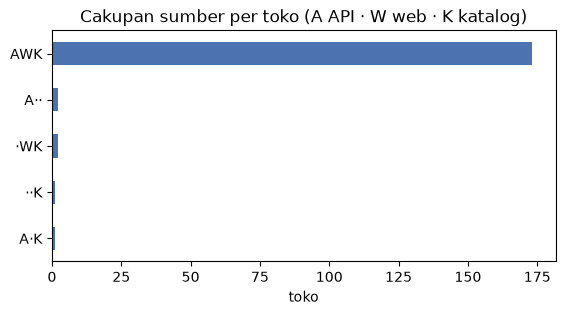

In [44]:
def modus_pertama(s: pd.Series):
    """Nilai terbanyak; bila seri, yang muncul lebih dulu di katalog."""
    n = s.value_counts()
    return s[s.map(n).eq(n.max())].iloc[0]


kat_toko = (katalog.groupby("id_toko", sort=True)
            .agg(provinsi_katalog=("provinsi_toko", modus_pertama),
                 n_provinsi_katalog=("provinsi_toko", "nunique"),
                 rating_katalog=("rating_toko", "mean"),
                 n_produk_katalog=("kode_produk", "size"))
            .reset_index())
# nama toko tidak dibersihkan Modul 4, jadi selalu dibaca dari produk.csv
nama_mentah = pd.read_csv(RAW / "produk.csv", dtype=str, keep_default_na=False).groupby("id_toko").nama_toko.first()
kat_toko["nama_toko_katalog"] = kat_toko.id_toko.map(nama_mentah)
api_toko = v2.copy()                                   # sumber API: v2 (field sudah diratakan)
semua_id = sorted(set(api_toko.id_toko) | set(toko_web.id_toko) | set(kat_toko.id_toko))
cakupan = pd.DataFrame({"id_toko": semua_id})
cakupan["ada_di_api"] = cakupan.id_toko.isin(api_toko.id_toko)
cakupan["ada_di_web"] = cakupan.id_toko.isin(toko_web.id_toko)
cakupan["ada_di_katalog"] = cakupan.id_toko.isin(kat_toko.id_toko)
pola = (cakupan.ada_di_api.map({True: "A", False: "·"}) + cakupan.ada_di_web.map({True: "W", False: "·"})
        + cakupan.ada_di_katalog.map({True: "K", False: "·"}))
print(f"{len(cakupan)} toko di gabungan ketiga sumber (A = API, W = web, K = katalog)")
print(pola.value_counts().to_string())
print("katalog tanpa API:", cakupan.id_toko[cakupan.ada_di_katalog & ~cakupan.ada_di_api].tolist())
print("API tanpa katalog:", cakupan.id_toko[cakupan.ada_di_api & ~cakupan.ada_di_katalog].tolist())

fig, ax = plt.subplots(figsize=(6.5, 3))
pola.value_counts().sort_values().plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_xlabel("toko"); ax.set_title("Cakupan sumber per toko (A API · W web · K katalog)")
fig.savefig(OUT / "02_cakupan_sumber.png", dpi=110, bbox_inches="tight")
plt.show()

### C.3 Provinsi dan rating: membandingkan nilai, bukan hanya keberadaan

In [45]:
rek = (cakupan.merge(api_toko[["id_toko", "provinsi", "rating", "nama_toko"]].rename(
           columns={"provinsi": "provinsi_api", "rating": "rating_api", "nama_toko": "nama_api"}), how="left")
       .merge(toko_web[["id_toko", "provinsi", "rating", "markup", "n_produk_web"]].rename(
           columns={"provinsi": "provinsi_web", "rating": "rating_web"}), how="left")
       .merge(kat_toko, how="left"))
both_k = rek.ada_di_katalog
print("toko katalog dengan >1 provinsi di antara produknya:",
      int((rek.n_provinsi_katalog > 1).sum()), "dari", int(both_k.sum()))
print(rek.n_provinsi_katalog.value_counts().sort_index().to_dict())
ak = rek.ada_di_api & rek.ada_di_katalog
print("provinsi API = modus katalog:", int((rek.provinsi_api == rek.provinsi_katalog)[ak].sum()), "dari", int(ak.sum()))
aw = rek.ada_di_api & rek.provinsi_web.notna()
print("provinsi API = web:", int((rek.provinsi_api == rek.provinsi_web)[aw].sum()), "dari", int(aw.sum()),
      "| web tanpa provinsi:", int((rek.ada_di_web & rek.provinsi_web.isna()).sum()))

rek["selisih_rating_web"] = (rek.rating_web - rek.rating_api).round(1)
rek["selisih_rating_katalog"] = (rek.rating_katalog - rek.rating_api).round(2)
beda_web = rek[rek.selisih_rating_web.abs() > 0.05]
print("rating web ≠ API:", len(beda_web), beda_web[["id_toko", "rating_api", "rating_web"]].values.tolist())
sama_kat = np.isclose(rek.rating_katalog, rek.rating_api.astype(float), atol=0.05 + 1e-9)
print("rating API = rata-rata rating katalog positif (selisih ≤ 0,05):",
      int(sama_kat[ak & rek.rating_api.notna()].sum()), "dari", int((ak & rek.rating_api.notna()).sum()))
sd_dalam = katalog.groupby("id_toko").rating_toko.std()
print(f"simpangan baku rating_toko di dalam satu toko (katalog): median {sd_dalam.median():.2f}")
rek.to_csv(OUT / "rekonsiliasi_toko_m07.csv", index=False)

toko katalog dengan >1 provinsi di antara produknya: 166 dari 177
{1.0: 11, 2.0: 34, 3.0: 34, 4.0: 44, 5.0: 34, 6.0: 14, 7.0: 4, 9.0: 2}
provinsi API = modus katalog: 174 dari 174
provinsi API = web: 169 dari 169 | web tanpa provinsi: 4
rating web ≠ API: 4 [['T044', 3.9, 3.6], ['T080', 3.9, 3.6], ['T081', 4.6, 4.4], ['T149', 4.3, 4.0]]
rating API = rata-rata rating katalog positif (selisih ≤ 0,05): 173 dari 173
simpangan baku rating_toko di dalam satu toko (katalog): median 0.49


### C.4 Harga: katalog vs etalase web

status_harga
sama              738
promo              45
berbeda            19
tidak_tersedia      3
web_saja            2
produk katalog dari toko yang punya halaman, tetapi tidak dipajang: 38
toko dengan produk web < produk katalog: 32 | toko web dengan 0 produk: 0
              count    min    max
status_harga                     
berbeda        19.0  1.051  1.143
promo          45.0  0.804  0.944


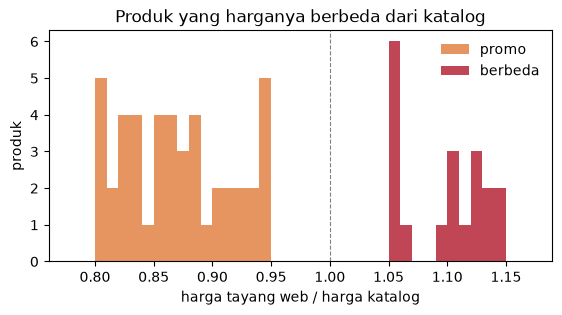

In [46]:
kat_harga = katalog[["kode_produk", "id_toko", "harga_katalog_rp"]]
pw = produk_web.merge(kat_harga, on=["kode_produk", "id_toko"], how="left", indicator=True)
pw["ada_di_katalog"] = pw.pop("_merge").eq("both")
pw["harga_katalog_rp"] = pw.harga_katalog_rp.astype("Int64")
benar = lambda m: m.fillna(False).to_numpy(dtype=bool)     # NA pada kolom Int64 dianggap tidak cocok
pw["status_harga"] = np.select(
    [~pw.ada_di_katalog.to_numpy(), benar(pw.harga_tayang_rp.isna()),
     benar(pw.harga_coret_rp.notna() & pw.harga_coret_rp.eq(pw.harga_katalog_rp)),
     benar(pw.harga_tayang_rp.eq(pw.harga_katalog_rp))],
    ["web_saja", "tidak_tersedia", "promo", "sama"], "berbeda")
print(pw.status_harga.value_counts().to_string())
tak_dipajang = kat_harga[kat_harga.id_toko.isin(toko_web.id_toko)].merge(
    produk_web[["kode_produk"]], how="left", indicator=True).query("_merge == 'left_only'")
print("produk katalog dari toko yang punya halaman, tetapi tidak dipajang:", len(tak_dipajang))
cek_toko = rek[rek.ada_di_web & rek.ada_di_katalog]
print("toko dengan produk web < produk katalog:", int((cek_toko.n_produk_web < cek_toko.n_produk_katalog).sum()),
      "| toko web dengan 0 produk:", int((rek.ada_di_web & rek.n_produk_web.eq(0)).sum()))
rasio = (pw.harga_tayang_rp / pw.harga_katalog_rp).astype(float)[pw.status_harga.isin(["promo", "berbeda"])]
print(rasio.groupby(pw.status_harga).describe()[["count", "min", "max"]].round(3))

fig, ax = plt.subplots(figsize=(6.5, 3))
for st, warna in [("promo", "#e07b39"), ("berbeda", "#b2182b")]:
    ax.hist(rasio[pw.status_harga[rasio.index].eq(st)], bins=np.arange(.78, 1.18, .01), alpha=.8, color=warna, label=st)
ax.axvline(1, color="gray", ls="--", lw=.8)
ax.set_xlabel("harga tayang web / harga katalog"); ax.set_ylabel("produk"); ax.legend(frameon=False)
ax.set_title("Produk yang harganya berbeda dari katalog")
fig.savefig(OUT / "03_selisih_harga.png", dpi=110, bbox_inches="tight")
plt.show()

produk_web_m07 = pw[["id_toko", "kode_produk", "nama_produk", "harga_teks", "harga_tayang_rp",
                     "harga_coret_rp", "harga_katalog_rp", "status_harga", "ada_di_katalog", "stok", "markup"]]
produk_web_m07.to_parquet(OUT / "produk_web_m07.parquet", index=False)

### C.5 Sumber mana dipercaya untuk kolom apa

In [47]:
sumber_kebenaran = pd.DataFrame([
    {"kolom": "nama_toko", "sumber_utama": "api", "cadangan": "web;katalog",
     "alasan": "API terstruktur dan bertanda updated_at; web dan katalog hanya salinan tampilan",
     "bukti": f"nama API = web pada {int((rek.nama_api == toko_web.set_index('id_toko').nama_toko.reindex(rek.id_toko).values).sum())} toko"},
    {"kolom": "provinsi", "sumber_utama": "api", "cadangan": "web;katalog",
     "alasan": "provinsi_toko katalog berbeda-beda di antara produk satu toko (cadangan terakhir: modus); web dinormalkan",
     "bukti": f"{int((rek.n_provinsi_katalog > 1).sum())} dari {int(both_k.sum())} toko katalog punya >1 provinsi; API = web pada {int((rek.provinsi_api == rek.provinsi_web)[aw].sum())} dari {int(aw.sum())}"},
    {"kolom": "kota", "sumber_utama": "api", "cadangan": "web",
     "alasan": "katalog tidak memuat kota", "bukti": f"web tanpa kota {int((rek.ada_di_web & toko_web.set_index('id_toko').kota.reindex(rek.id_toko).isna().values).sum())} toko"},
    {"kolom": "rating_toko", "sumber_utama": "api", "cadangan": "web;katalog",
     "alasan": "web menampilkan rating basi pada sebagian toko; rating katalog per produk dan memuat penanda 0,0 (cadangan terakhir: rata-rata rating positif)",
     "bukti": f"web ≠ API pada {len(beda_web)} toko; API = rata-rata rating positif katalog pada {int(sama_kat[ak & rek.rating_api.notna()].sum())} toko"},
    {"kolom": "jumlah_ulasan", "sumber_utama": "api", "cadangan": "web",
     "alasan": "mengikuti sumber rating agar rating dan jumlah ulasan sepasang", "bukti": "katalog tidak memuat jumlah ulasan"},
    {"kolom": "harga_katalog_rp", "sumber_utama": "katalog", "cadangan": "-",
     "alasan": "harga daftar resmi penjual; harga web adalah harga tayang (promo/terbaru)",
     "bukti": f"promo {int(pw.status_harga.eq('promo').sum())}, berbeda {int(pw.status_harga.eq('berbeda').sum())} produk"},
    {"kolom": "harga_tayang_rp", "sumber_utama": "web", "cadangan": "-",
     "alasan": "harga yang benar-benar dilihat pembeli saat diambil; disimpan terpisah, tidak menimpa katalog",
     "bukti": f"{int(pw.harga_tayang_rp.notna().sum())} produk berharga tayang"},
])
sumber_kebenaran.to_csv(OUT / "sumber_kebenaran_m07.csv", index=False)
sumber_kebenaran

,kolom,sumber_utama,cadangan,alasan,bukti
0,nama_toko,api,web;katalog,API terstruktur dan bertanda updated_at; web d...,nama API = web pada 173 toko
1,provinsi,api,web;katalog,provinsi_toko katalog berbeda-beda di antara p...,166 dari 177 toko katalog punya >1 provinsi; A...
2,kota,api,web,katalog tidak memuat kota,web tanpa kota 5 toko
3,rating_toko,api,web;katalog,web menampilkan rating basi pada sebagian toko...,web ≠ API pada 4 toko; API = rata-rata rating ...
4,jumlah_ulasan,api,web,mengikuti sumber rating agar rating dan jumlah...,katalog tidak memuat jumlah ulasan
5,harga_katalog_rp,katalog,-,harga daftar resmi penjual; harga web adalah h...,"promo 45, berbeda 19 produk"
6,harga_tayang_rp,web,-,harga yang benar-benar dilihat pembeli saat di...,804 produk berharga tayang


**Pembahasan C**

| Pola (A API · W web · K katalog) | Toko | Siapa |
|---|---:|---|
| `AWK` | 173 | |
| `A·K` | 1 | `T068`: halaman 404 |
| `·WK` | 2 | `T100`, `T135`: tanpa profil API, profil hanya dari web |
| `··K` | 1 | `T140`: hanya katalog (tanpa profil API, halaman 404) |
| `A··` | 2 | `T035`, `T092`: terdaftar di API, belum punya produk |
| **gabungan** | **179** | |

- Jumlah API (176), katalog (177), dan web (175) hampir sama, tetapi **himpunannya berbeda**;
  hanya 173 toko ada di ketiganya.
- `provinsi_toko` katalog berbeda-beda di antara produk satu toko
  (**166 dari 177** toko punya lebih dari satu provinsi; sebaran 1–9 provinsi). Kolom itu bukan
  atribut toko. Provinsi API = modus katalog pada 174 dari 174 toko dan = web pada 169 dari 169
  halaman yang memuat lokasi.
- Rating: API = rata-rata rating katalog positif (173 dari 173, selisih ≤ 0,05). Web
  menampilkan rating **basi** pada 4 toko (`T044`, `T080`, `T081`, `T149`; 0,2–0,4 lebih
  rendah). Rating katalog per produk bervariasi (sd median 0,49) dan memuat penanda 0,0.
- Harga (807 produk etalase): sama 738, **promo 45** (harga coret = katalog, rasio 0,80–0,94),
  **berbeda 19** (naik 5–14% tanpa harga coret: katalog basi), tidak tersedia 3, web saja 2
  (`LS-KER-9001`, `LS-KER-9002`). 38 produk katalog tidak dipajang. Harga katalog **tidak**
  ditimpa harga web; keduanya disimpan dengan `status_harga`.

## Bagian D — ETL ke SQLite yang idempoten

### D.1 Mengapa `to_sql(if_exists="append")` berbahaya

In [48]:
coba = sqlite3.connect(":memory:")
for ke in (1, 2):
    v2.to_sql("toko", coba, if_exists="append", index=False)
    print(f"setelah jalan ke-{ke}: {coba.execute('SELECT COUNT(*) FROM toko').fetchone()[0]} baris, "
          f"{coba.execute('SELECT COUNT(DISTINCT id_toko) FROM toko').fetchone()[0]} toko")
coba.close()

setelah jalan ke-1: 176 baris, 176 toko
setelah jalan ke-2: 352 baris, 176 toko


### D.2 Skema: staging, tabel akhir dengan kunci primer, dan `etl_run`

In [49]:
DB = OUT / "lapak_m07.sqlite"
SKEMA_SQL = """
CREATE TABLE IF NOT EXISTS stg_toko_api   (run_id TEXT, id_toko TEXT, nama_toko TEXT, provinsi TEXT, kota TEXT,
    rating REAL, jumlah_ulasan INTEGER, status TEXT, tanggal_bergabung TEXT, updated_at TEXT);
CREATE TABLE IF NOT EXISTS stg_toko_web   (run_id TEXT, id_toko TEXT, nama_toko TEXT, provinsi TEXT, kota TEXT,
    rating REAL, jumlah_ulasan INTEGER, markup TEXT, url TEXT, n_produk_web INTEGER);
CREATE TABLE IF NOT EXISTS stg_produk_web (run_id TEXT, id_toko TEXT, kode_produk TEXT, nama_produk TEXT,
    harga_teks TEXT, harga_tayang_rp INTEGER, harga_coret_rp INTEGER, harga_katalog_rp INTEGER,
    status_harga TEXT, ada_di_katalog INTEGER, stok INTEGER, markup TEXT);
CREATE TABLE IF NOT EXISTS stg_toko       (run_id TEXT, id_toko TEXT, nama_toko TEXT, provinsi TEXT, kota TEXT,
    rating_toko REAL, jumlah_ulasan INTEGER, status TEXT, tanggal_bergabung TEXT, updated_at TEXT,
    sumber_profil TEXT, provinsi_sumber TEXT, ada_di_api INTEGER, ada_di_web INTEGER, ada_di_katalog INTEGER,
    n_produk_katalog INTEGER, n_produk_web INTEGER);

CREATE TABLE IF NOT EXISTS toko_api (
    id_toko TEXT PRIMARY KEY, nama_toko TEXT NOT NULL, provinsi TEXT NOT NULL, kota TEXT,
    rating REAL CHECK (rating IS NULL OR rating BETWEEN 1 AND 5), jumlah_ulasan INTEGER CHECK (jumlah_ulasan >= 0),
    status TEXT NOT NULL, tanggal_bergabung TEXT, updated_at TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS toko_web (
    id_toko TEXT PRIMARY KEY, nama_toko TEXT, provinsi TEXT, kota TEXT, rating REAL, jumlah_ulasan INTEGER,
    markup TEXT, url TEXT NOT NULL, n_produk_web INTEGER NOT NULL);
CREATE TABLE IF NOT EXISTS produk_web (
    id_toko TEXT NOT NULL, kode_produk TEXT NOT NULL, nama_produk TEXT, harga_teks TEXT,
    harga_tayang_rp INTEGER CHECK (harga_tayang_rp IS NULL OR harga_tayang_rp > 0), harga_coret_rp INTEGER,
    harga_katalog_rp INTEGER, status_harga TEXT NOT NULL, ada_di_katalog INTEGER NOT NULL, stok INTEGER, markup TEXT,
    PRIMARY KEY (id_toko, kode_produk));
CREATE TABLE IF NOT EXISTS toko (
    id_toko TEXT PRIMARY KEY, nama_toko TEXT NOT NULL, provinsi TEXT NOT NULL, kota TEXT,
    rating_toko REAL, jumlah_ulasan INTEGER, status TEXT, tanggal_bergabung TEXT, updated_at TEXT,
    sumber_profil TEXT NOT NULL CHECK (sumber_profil IN ('api', 'web', 'katalog')),
    provinsi_sumber TEXT NOT NULL, ada_di_api INTEGER NOT NULL, ada_di_web INTEGER NOT NULL,
    ada_di_katalog INTEGER NOT NULL, n_produk_katalog INTEGER NOT NULL, n_produk_web INTEGER);
CREATE TABLE IF NOT EXISTS etl_run (
    run_id TEXT NOT NULL, jenis TEXT NOT NULL CHECK (jenis IN ('penuh', 'inkremental')), sumber TEXT NOT NULL,
    waktu_mulai TEXT NOT NULL, waktu_selesai TEXT NOT NULL, baris_masuk INTEGER NOT NULL,
    baris_ditolak INTEGER NOT NULL, baris_ditulis INTEGER NOT NULL, watermark TEXT,
    PRIMARY KEY (run_id, sumber));
"""
KUNCI_TABEL = {"toko_api": ["id_toko"], "toko_web": ["id_toko"],
               "produk_web": ["id_toko", "kode_produk"], "toko": ["id_toko"]}


@contextmanager
def buka_db(path: Path = DB):
    """Satu koneksi = satu transaksi: commit bila berhasil, rollback bila galat, lalu ditutup."""
    con = sqlite3.connect(path)
    try:
        with con:
            yield con
    finally:
        con.close()


with buka_db() as con:
    con.executescript(SKEMA_SQL)
    print([r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")])

['etl_run', 'produk_web', 'stg_produk_web', 'stg_toko', 'stg_toko_api', 'stg_toko_web', 'toko', 'toko_api', 'toko_web']


### D.3 Muat lewat staging dengan upsert

In [50]:
def muat(con: sqlite3.Connection, df: pd.DataFrame, tabel: str, run_id: str) -> int:
    """Staging -> tabel akhir. Staging dikosongkan dulu; tabel akhir di-upsert per kunci primer."""
    kunci = KUNCI_TABEL[tabel]
    kolom = [c for c in df.columns]
    con.execute(f"DELETE FROM stg_{tabel}")
    con.executemany(
        f"INSERT INTO stg_{tabel} (run_id, {', '.join(kolom)}) VALUES (?, {', '.join('?' * len(kolom))})",
        [(run_id, *[None if pd.isna(v) else (v.item() if hasattr(v, "item") else v) for v in baris])
         for baris in df.itertuples(index=False)])
    ubah = [c for c in kolom if c not in kunci]
    sebelum = con.total_changes
    con.execute(
        f"INSERT INTO {tabel} ({', '.join(kolom)}) SELECT {', '.join(kolom)} FROM stg_{tabel} WHERE true "
        f"ON CONFLICT ({', '.join(kunci)}) DO UPDATE SET {', '.join(f'{c} = excluded.{c}' for c in ubah)} "
        f"WHERE {' OR '.join(f'{tabel}.{c} IS NOT excluded.{c}' for c in ubah)}")
    return con.total_changes - sebelum


def sidik_tabel(con: sqlite3.Connection, tabel: str) -> str:
    """SHA-256 isi tabel terurut menurut kunci primer: dua jalan identik = sidik sama."""
    urut = ", ".join(KUNCI_TABEL[tabel])
    baris = con.execute(f"SELECT * FROM {tabel} ORDER BY {urut}").fetchall()
    return hashlib.sha256(repr(baris).encode()).hexdigest()[:16]

### D.4 Satu fungsi ETL, dijalankan dua kali

In [51]:
KOLOM_API = ["id_toko", "nama_toko", "provinsi", "kota", "rating", "jumlah_ulasan", "status",
             "tanggal_bergabung", "updated_at"]
KOLOM_TOKO = ["id_toko", "nama_toko", "provinsi", "kota", "rating_toko", "jumlah_ulasan", "status",
              "tanggal_bergabung", "updated_at", "sumber_profil", "provinsi_sumber", "ada_di_api",
              "ada_di_web", "ada_di_katalog", "n_produk_katalog", "n_produk_web"]


KOLOM_PROFIL = ["nama_toko", "provinsi", "kota", "rating_toko", "jumlah_ulasan"]


def prioritas_dari(tabel: pd.DataFrame) -> dict[str, list[str]]:
    """{kolom: [sumber_utama, cadangan, ...]} dari tabel sumber kebenaran (Bagian C.5)."""
    return {r.kolom: [r.sumber_utama] + [x.strip() for x in str(r.cadangan).split(";")
                                          if x.strip() not in ("", "-")]
            for r in tabel.itertuples(index=False)}


def integrasikan(api_df: pd.DataFrame, web_df: pd.DataFrame, kat_df: pd.DataFrame,
                 prioritas: dict[str, list[str]]) -> pd.DataFrame:
    """Satu baris per toko dari gabungan tiga sumber.

    Untuk setiap kolom profil dipakai nilai pertama yang tersedia menurut urutan
    `prioritas`; sumber yang dipakai untuk nama_toko dan provinsi dicatat.
    """
    ids = sorted(set(api_df.id_toko) | set(web_df.id_toko) | set(kat_df.id_toko))
    kat = kat_df.rename(columns={"nama_toko_katalog": "nama_toko", "provinsi_katalog": "provinsi",
                                 "rating_katalog": "rating_toko"})
    sumber = {
        "api": api_df.rename(columns={"rating": "rating_toko"}).set_index("id_toko").reindex(ids),
        "web": web_df.rename(columns={"rating": "rating_toko"}).set_index("id_toko").reindex(ids),
        "katalog": kat.assign(rating_toko=kat.rating_toko.round(1)).set_index("id_toko").reindex(ids),
    }
    hasil = pd.DataFrame(index=pd.Index(ids, name="id_toko"))
    asal = {}
    for kolom in KOLOM_PROFIL:
        nilai = pd.Series(None, index=hasil.index, dtype=object)
        dari = pd.Series(None, index=hasil.index, dtype=object)
        for s in prioritas[kolom]:
            if kolom not in sumber[s]:
                continue
            isi = sumber[s][kolom]
            pakai = dari.isna() & isi.notna()
            nilai[pakai], dari[pakai] = isi[pakai], s
        hasil[kolom], asal[kolom] = nilai, dari
    a = sumber["api"]
    hasil["status"], hasil["tanggal_bergabung"], hasil["updated_at"] = a.status, a.tanggal_bergabung, a.updated_at
    hasil["sumber_profil"], hasil["provinsi_sumber"] = asal["nama_toko"], asal["provinsi"]
    hasil["ada_di_api"] = a.nama_toko.notna()
    hasil["ada_di_web"] = sumber["web"].url.notna()
    hasil["ada_di_katalog"] = sumber["katalog"].n_produk_katalog.notna()
    hasil["n_produk_katalog"] = sumber["katalog"].n_produk_katalog.fillna(0).astype(int)
    hasil["n_produk_web"] = sumber["web"].n_produk_web
    return (hasil.reset_index()
            .astype({"rating_toko": "float64", "jumlah_ulasan": "Int64", "n_produk_web": "Int64"}))


def ekstrak_api(klien: Klien, path: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Ambil v2, ratakan, validasi; kembalikan (diterima, ditolak)."""
    item, _ = ambil_semua(klien, path, kunci_data="items")
    df = pd.DataFrame([ratakan_v2(x) for x in item], columns=KOLOM_API)
    tolak = (df.id_toko.isna() | df.nama_toko.isna() | df.provinsi.isna() | df.updated_at.isna()
             | df.duplicated("id_toko", keep="first"))
    return df[~tolak].reset_index(drop=True), df[tolak]


def catat_run(con, run_id, jenis, sumber, mulai, masuk, ditolak, ditulis, watermark=None) -> None:
    con.execute("INSERT OR REPLACE INTO etl_run VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)",
                (run_id, jenis, sumber, mulai, datetime.now(timezone.utc).isoformat(timespec="seconds"),
                 int(masuk), int(ditolak), int(ditulis), watermark))


def jalankan_etl(klien: Klien, toko_web: pd.DataFrame, produk_web: pd.DataFrame,
                 kat_toko: pd.DataFrame) -> dict:
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    mulai = datetime.now(timezone.utc).isoformat(timespec="seconds")
    api_df, api_tolak = ekstrak_api(klien, "/api/v2/toko?page=1&per_page=50")
    toko_df = integrasikan(api_df, toko_web, kat_toko, PRIORITAS)
    kolom_web = ["id_toko", "nama_toko", "provinsi", "kota", "rating", "jumlah_ulasan", "markup", "url", "n_produk_web"]
    with buka_db() as con:              # satu transaksi: semua tabel atau tidak sama sekali
        ditulis = {
            "api_v2": muat(con, api_df, "toko_api", run_id),
            "situs": muat(con, toko_web[kolom_web], "toko_web", run_id),
            "situs_produk": muat(con, produk_web, "produk_web", run_id),
            "integrasi": muat(con, toko_df[KOLOM_TOKO], "toko", run_id),
        }
        masuk = {"api_v2": len(api_df) + len(api_tolak), "situs": len(toko_web),
                 "situs_produk": len(produk_web), "integrasi": len(toko_df)}
        tolak = {"api_v2": len(api_tolak), "situs": len(halaman_gagal), "situs_produk": 0, "integrasi": 0}
        for s in ditulis:
            catat_run(con, run_id, "penuh", s, mulai, masuk[s], tolak[s], ditulis[s],
                      api_df.updated_at.max() if s == "api_v2" else None)
        sidik = {t: sidik_tabel(con, t) for t in KUNCI_TABEL}
    return {"run_id": run_id, "ditulis": ditulis, "sidik": sidik}


PRIORITAS = prioritas_dari(sumber_kebenaran)      # keputusan Bagian C.5, bukan ketikan ulang
print(PRIORITAS)
produk_web_muat = pd.read_parquet(OUT / "produk_web_m07.parquet").astype({"ada_di_katalog": int})
hasil_1 = jalankan_etl(api2, toko_web, produk_web_muat, kat_toko)
hasil_2 = jalankan_etl(api2, toko_web, produk_web_muat, kat_toko)
print("jalan 1 menulis:", hasil_1["ditulis"])
print("jalan 2 menulis:", hasil_2["ditulis"])
print("sidik sama:", hasil_1["sidik"] == hasil_2["sidik"], hasil_2["sidik"])
assert hasil_1["sidik"] == hasil_2["sidik"], "ETL tidak idempoten"

{'nama_toko': ['api', 'web', 'katalog'], 'provinsi': ['api', 'web', 'katalog'], 'kota': ['api', 'web'], 'rating_toko': ['api', 'web', 'katalog'], 'jumlah_ulasan': ['api', 'web'], 'harga_katalog_rp': ['katalog'], 'harga_tayang_rp': ['web']}
jalan 1 menulis: {'api_v2': 14, 'situs': 0, 'situs_produk': 0, 'integrasi': 15}
jalan 2 menulis: {'api_v2': 0, 'situs': 0, 'situs_produk': 0, 'integrasi': 0}
sidik sama: True {'toko_api': '12496f7752bf303b', 'toko_web': 'e22b695f919308a8', 'produk_web': '62dc09d7479b76a5', 'toko': 'e1b926b0bbc1c0eb'}


In [52]:
def ekspor_toko(path_db: Path = DB) -> pd.DataFrame:
    with buka_db(path_db) as con:
        t = pd.read_sql("SELECT * FROM toko ORDER BY id_toko", con)
    t = t.astype({"ada_di_api": bool, "ada_di_web": bool, "ada_di_katalog": bool,
                  "jumlah_ulasan": "Int64", "n_produk_katalog": "int64", "n_produk_web": "Int64",
                  "rating_toko": "float64"})
    t["tanggal_bergabung"] = pd.to_datetime(t.tanggal_bergabung, format="%Y-%m-%d")
    t["updated_at"] = pd.to_datetime(t.updated_at, format="%Y-%m-%dT%H:%M:%SZ", utc=True)
    t.to_parquet(OUT / "toko_m07.parquet", index=False)
    return t


toko_m07 = ekspor_toko()
with buka_db() as con:
    print(pd.read_sql("SELECT run_id, jenis, sumber, baris_masuk, baris_ditolak, baris_ditulis, watermark "
                      "FROM etl_run ORDER BY run_id, sumber", con).to_string(index=False))
    print({t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in KUNCI_TABEL})
log_req = simpan_log_permintaan(api, api2, situs)
print(toko_m07.dtypes.to_string())
toko_m07.sumber_profil.value_counts()

                run_id       jenis       sumber  baris_masuk  baris_ditolak  baris_ditulis            watermark
20261111T075512153806Z       penuh       api_v2          176              0            176 2026-06-30T22:35:11Z
20261111T075512153806Z       penuh    integrasi          179              0            179                  NaN
20261111T075512153806Z       penuh        situs          175              2            175                  NaN
20261111T075512153806Z       penuh situs_produk          807              0            807                  NaN
20261111T075513049741Z       penuh       api_v2          176              0              0 2026-06-30T22:35:11Z
20261111T075513049741Z       penuh    integrasi          179              0              0                  NaN
20261111T075513049741Z       penuh        situs          175              2              0                  NaN
20261111T075513049741Z       penuh situs_produk          807              0              0              

sumber_profil
api        179
web          2
katalog      1
Name: count, dtype: int64

### D.5 Log keputusan

In [53]:
import shutil

KOLOM_LOG = ["id", "modul", "sumber_kolom", "temuan", "bukti", "tindakan", "alasan",
             "baris_terdampak", "id_anomali"]


def catat_keputusan(baris: list[dict], path: Path = LOG) -> pd.DataFrame:
    """Tulis ulang baris log dengan id yang sama agar notebook aman dijalankan berulang."""
    lama = (pd.read_csv(path, dtype=str, keep_default_na=False) if path.exists()
            else pd.DataFrame(columns=KOLOM_LOG))
    baru = pd.DataFrame(baris, columns=KOLOM_LOG).astype(str)
    log = pd.concat([lama[~lama.id.isin(baru.id)], baru]).sort_values("id")
    log.to_csv(path, index=False)
    shutil.copyfile(path, MODUL / path.name)   # salinan untuk ZIP tugas
    return log


lg = log_req
n500 = int((lg.status == 500).sum())
n429 = sum(x.status_code == 429 for x in ledakan)
ganda = validasi_api[validasi_api.masalah.str.startswith("kunci ganda")]
teks_rating = validasi_api[validasi_api.kolom.eq("rating")]
log = catat_keputusan([
    {"id": "K-07-001", "modul": 7, "sumber_kolom": "api_v1.toko",
     "temuan": "pola pagination buku berhenti diam-diam pada galat 500 halaman 3",
     "bukti": f"cara naif {len(naif)} rekaman vs total {info_v1['total']}; log: {n500} respons 500 pada halaman 3 (v1 dan v2), semuanya pulih lewat percobaan ulang",
     "tindakan": "ikuti tautan next sampai null; 5xx dicoba ulang dengan backoff eksponensial 0,5-4 s, maksimal 5 percobaan",
     "alasan": "galat sementara bukan akhir data; berhenti tanpa galat menghasilkan data terpotong yang tampak lengkap",
     "baris_terdampak": info_v1["total"] - len(naif), "id_anomali": "-"},
    {"id": "K-07-002", "modul": 7, "sumber_kolom": "api_v1.toko;api_v2.toko",
     "temuan": "server membatasi laju 5 permintaan per detik (429 + Retry-After)",
     "bukti": f"8 permintaan beruntun: {n429} dijawab 429 dengan Retry-After {ledakan[-1].headers.get('Retry-After')}; klien berjeda: {int((lg.status == 429).sum())} respons 429",
     "tindakan": "jeda minimum 0,25 s antarpermintaan; 429 ditunggu sesuai Retry-After lalu dicoba ulang",
     "alasan": "mengikuti batas penyedia; percobaan ulang tanpa jeda memperpanjang pemblokiran",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-07-003", "modul": 7, "sumber_kolom": "api_v1.toko.id_toko",
     "temuan": "satu toko muncul dua kali di batas halaman; total menghitung salinannya",
     "bukti": f"{len(rekam_v1)} rekaman, {v1.id_toko.nunique()} id unik; salinan {ganda.id_toko.tolist()} identik",
     "tindakan": "salinan identik dibuang; kunci unik id_toko diuji sebelum dimuat",
     "alasan": "total = jumlah katalog (177) adalah kebetulan, bukan bukti kelengkapan",
     "baris_terdampak": len(ganda), "id_anomali": "-"},
    {"id": "K-07-004", "modul": 7, "sumber_kolom": "api_v1.toko.rating",
     "temuan": "rating bertipe teks berkoma pada sebagian rekaman v1",
     "bukti": f"{len(teks_rating)} rekaman ({', '.join(teks_rating.id_toko)}); setelah koma -> titik seluruh rating v1 = v2",
     "tindakan": "dikonversi ke float dengan koma -> titik; ETL memakai v2 yang bertipe benar",
     "alasan": "to_numeric(errors='coerce') akan mengubahnya menjadi NaN tanpa pesan; v2 membuktikan nilainya",
     "baris_terdampak": len(teks_rating), "id_anomali": "-"},
    {"id": "K-07-005", "modul": 7, "sumber_kolom": "situs.pemilik",
     "temuan": "direktori menautkan halaman kontak pemilik yang dilarang robots.txt dan memuat data pribadi",
     "bukti": f"{len(terlarang)} tautan /situs/pemilik/ dilarang; 0 permintaan ke jalur itu pada log",
     "tindakan": "tautan disaring dengan RobotFileParser.can_fetch sebelum diminta; nama dan telepon pemilik tidak dikumpulkan",
     "alasan": "robots.txt dan prinsip minimisasi data UU PDP; nomor pemilik tidak diperlukan analisis toko",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-07-006", "modul": 7, "sumber_kolom": "situs.toko",
     "temuan": "satu halaman profil memakai markup lama (tabel) sehingga selektor baru mengembalikan 0 produk",
     "bukti": f"{toko_web.id_toko[toko_web.markup.eq('lama')].tolist()}: 0 produk dengan selektor baru, {int(toko_web.n_produk_web[toko_web.markup.eq('lama')].iloc[0])} dengan pengurai lama",
     "tindakan": "pengurai kedua untuk markup lama; provinsi singkatan dinormalkan; halaman tak dikenal dicatat",
     "alasan": "nol produk tanpa galat adalah kegagalan senyap; jumlah produk per toko diuji terhadap katalog",
     "baris_terdampak": int(toko_web.n_produk_web[toko_web.markup.eq("lama")].iloc[0]), "id_anomali": "-"},
    {"id": "K-07-007", "modul": 7, "sumber_kolom": "situs.toko",
     "temuan": "halaman profil 404 dan elemen hilang",
     "bukti": f"404: {', '.join(Path(u).stem for u in halaman_gagal.url)}; tanpa lokasi {int((toko_web.markup.eq('baru') & toko_web.provinsi.isna()).sum())}; harga 'Hubungi penjual' {int(produk_web.harga_tayang_rp.isna().sum())}",
     "tindakan": "halaman gagal dicatat di halaman_gagal_m07.csv; elemen hilang menjadi NA, tidak 0",
     "alasan": "tidak ada halaman yang hilang tanpa catatan; NA jujur, 0 adalah nilai palsu",
     "baris_terdampak": len(halaman_gagal), "id_anomali": "-"},
    {"id": "K-07-008", "modul": 7, "sumber_kolom": "produk.provinsi_toko;api_v2.toko.wilayah.provinsi",
     "temuan": "provinsi_toko katalog berbeda-beda di antara produk satu toko",
     "bukti": f"{int((rek.n_provinsi_katalog > 1).sum())} dari {int(both_k.sum())} toko katalog punya >1 provinsi; API = modus katalog pada {int((rek.provinsi_api == rek.provinsi_katalog)[ak].sum())} dari {int(ak.sum())}",
     "tindakan": "provinsi toko diambil dari API, cadangan web (dinormalkan), lalu modus katalog; provinsi_sumber dicatat",
     "alasan": "atribut toko harus satu nilai per toko; katalog menyimpan provinsi per produk",
     "baris_terdampak": int((rek.n_provinsi_katalog > 1).sum()), "id_anomali": "-"},
    {"id": "K-07-009", "modul": 7, "sumber_kolom": "api_v2.toko.ulasan.rating_rata;situs.toko.rating;produk.rating_toko",
     "temuan": "rating toko berbeda antarsumber",
     "bukti": f"web ≠ API pada {len(beda_web)} toko ({', '.join(beda_web.id_toko)}); API = rata-rata rating positif katalog",
     "tindakan": "rating_toko dari API; cadangan web, lalu rata-rata rating positif katalog",
     "alasan": "API terstruktur dan berstempel waktu; web menampilkan nilai basi; katalog per produk dengan penanda 0,0",
     "baris_terdampak": len(beda_web), "id_anomali": "A-19"},
    {"id": "K-07-010", "modul": 7, "sumber_kolom": "situs.produk.harga;produk.harga_katalog",
     "temuan": "harga tayang web berbeda dari harga katalog",
     "bukti": f"promo {int(pw.status_harga.eq('promo').sum())}, berbeda {int(pw.status_harga.eq('berbeda').sum())}, tidak tersedia {int(pw.status_harga.eq('tidak_tersedia').sum())}, web saja {int(pw.status_harga.eq('web_saja').sum())}",
     "tindakan": "harga web disimpan sebagai harga_tayang_rp dengan status_harga; harga_katalog_rp tidak ditimpa",
     "alasan": "keduanya benar untuk pertanyaan berbeda: daftar harga penjual vs harga yang dilihat pembeli",
     "baris_terdampak": int(pw.status_harga.isin(["promo", "berbeda"]).sum()), "id_anomali": "-"},
    {"id": "K-07-011", "modul": 7, "sumber_kolom": "lapak_m07.sqlite",
     "temuan": "append biasa menggandakan tabel setiap kali ETL dijalankan",
     "bukti": f"to_sql append dua kali: {2 * len(v2)} baris untuk {len(v2)} toko; upsert dua jalan: sidik tabel sama",
     "tindakan": "staging -> upsert INSERT ... ON CONFLICT per kunci primer; waktu muat hanya di etl_run",
     "alasan": "ETL harus aman diulang; kolom waktu muat di tabel akhir membuat dua jalan identik tampak berbeda",
     "baris_terdampak": 0, "id_anomali": "-"},
])
SRV.stop()                         # server edisi 1 tidak dipakai lagi
log[log.id.str.startswith("K-07")][["id", "sumber_kolom", "baris_terdampak"]]

,id,sumber_kolom,baris_terdampak
0,K-07-001,api_v1.toko,137
1,K-07-002,api_v1.toko;api_v2.toko,0
2,K-07-003,api_v1.toko.id_toko,1
3,K-07-004,api_v1.toko.rating,3
4,K-07-005,situs.pemilik,0
5,K-07-006,situs.toko,7
6,K-07-007,situs.toko,2
7,K-07-008,produk.provinsi_toko;api_v2.toko.wilayah.provinsi,166
8,K-07-009,api_v2.toko.ulasan.rating_rata;situs.toko.rati...,4
9,K-07-010,situs.produk.harga;produk.harga_katalog,64


**Pembahasan D**

- `to_sql(if_exists="append")` dua kali → **352 baris untuk 176 toko**.
- Upsert lewat staging: jalan 1 menulis api_v2 176, situs 175, situs_produk 807, integrasi 179;
  **jalan 2 menulis 0** pada keempat tabel dan **sidik keempat tabel sama**. Itu definisi
  operasional idempoten modul ini. Kolom seperti `dimuat_pada` di tabel akhir akan merusak
  uji ini; waktu muat hanya dicatat di `etl_run`.
- `etl_run`: 4 baris per jalan (api_v2, situs, situs_produk, integrasi) dengan baris_masuk,
  baris_ditolak (situs: 2 halaman 404), baris_ditulis, dan watermark `2026-06-30T22:35:11Z`.
- `toko_m07.parquet` setelah Bagian D: **179 toko** (`sumber_profil` api 176, web 2, katalog 1).

## Latihan 7.1 — Endpoint Flask sendiri: ringkasan per provinsi

**Dinilai.** Kerjakan di laboratorium. Tulis kode, hasil uji, dan alasan Anda pada **`dw-module-07/latihan-endpoint.md`**, lalu unggah ke tugas *Latihan Mandiri di Lab — Modul 07*.

Bangun endpoint `GET /api/v1/ringkasan-provinsi` dengan Flask (Bab 8.2.3) yang
meringkas **katalog** per provinsi **toko**: `n_produk`, `n_toko`, `median_harga_katalog_rp`, dan
`rata_rating_toko`. Endpoint menerima parameter opsional `?provinsi=`, menolak permintaan tanpa
`X-API-Key` (401), dan menjawab 404 untuk provinsi yang tidak dikenal. Uji dengan
`app.test_client()`, bukan dengan menjalankan server: sekurang-kurangnya satu uji untuk setiap
kode status dan satu uji rekonsiliasi (jumlah `n_produk` seluruh provinsi = jumlah produk katalog).
Simpan respons lengkap ke `keluaran/ringkasan_provinsi_m07.json`.

Sebelum menulis kode, putuskan: provinsi toko diambil dari mana? Periksa jawaban Anda dengan
menjumlahkan `n_toko` seluruh provinsi.

In [54]:
from flask import Flask, jsonify, request as req_flask

def ringkas_provinsi(katalog: pd.DataFrame, toko: pd.DataFrame) -> list[dict]:
    """Ringkasan katalog per provinsi TOKO.

    Keputusan: provinsi_toko di katalog berbeda-beda di antara produk satu toko (Bagian C.3),
    jadi bukan atribut toko. Provinsi diambil dari tabel `toko` (API, cadangan web, lalu modus
    katalog) sehingga setiap toko tepat satu provinsi dan sum(n_toko) = jumlah toko di katalog.
    """
    peta = toko.drop_duplicates("id_toko").set_index("id_toko")
    k = katalog.assign(provinsi=katalog.id_toko.map(peta.provinsi))
    assert k.provinsi.notna().all(), "ada toko katalog tanpa provinsi di tabel toko"
    per_produk = k.groupby("provinsi").agg(
        n_produk=("kode_produk", "size"), n_toko=("id_toko", "nunique"),
        median_harga_katalog_rp=("harga_katalog_rp", "median"))
    # rating dihitung per TOKO (bukan per produk) agar toko berproduk banyak tidak berbobot lebih
    tk = (k[["id_toko", "provinsi"]].drop_duplicates("id_toko")
          .assign(rating_toko=lambda d: d.id_toko.map(peta.rating_toko)))
    rating = tk.groupby("provinsi").rating_toko.mean()      # NaN (toko tanpa rating) dilewati
    hasil = per_produk.join(rating.rename("rata_rating_toko")).reset_index().sort_values("provinsi")
    return [{"provinsi": r.provinsi, "n_produk": int(r.n_produk), "n_toko": int(r.n_toko),
             "median_harga_katalog_rp": float(r.median_harga_katalog_rp),
             "rata_rating_toko": None if pd.isna(r.rata_rating_toko) else round(float(r.rata_rating_toko), 2)}
            for r in hasil.itertuples(index=False)]


def buat_app_ringkasan(katalog: pd.DataFrame, toko: pd.DataFrame, api_key: str = API_KEY) -> Flask:
    app = Flask("ringkasan_provinsi")
    app.json.ensure_ascii = False
    app.json.sort_keys = False
    # TODO: @app.get("/api/v1/ringkasan-provinsi") -> {"data": [{"provinsi", "n_produk", "n_toko",
    #       "median_harga_katalog_rp", "rata_rating_toko"}, ...], "jumlah": ...}
    #       ?provinsi= opsional; 401 tanpa X-API-Key; 404 untuk provinsi yang tidak dikenal
    tabel = ringkas_provinsi(katalog, toko)            # dihitung sekali; data tidak berubah
    dikenal = {r["provinsi"].casefold(): r for r in tabel}

    def galat(kode: int, pesan: str):
        r = jsonify({"error": pesan, "status": kode})
        r.status_code = kode
        return r

    @app.get("/api/v1/ringkasan-provinsi")
    def ringkasan_provinsi():
        kunci = req_flask.headers.get("X-API-Key")
        if not kunci:
            return galat(401, "header X-API-Key wajib diisi")
        if kunci != api_key:
            return galat(403, "X-API-Key tidak dikenal")
        minta = req_flask.args.get("provinsi")
        if minta is None:
            data = tabel
        else:
            baris = dikenal.get(minta.strip().casefold())
            if baris is None:
                return galat(404, f"provinsi '{minta}' tidak dikenal; pilihan: "
                                  + ", ".join(r["provinsi"] for r in tabel))
            data = [baris]
        return jsonify({"data": data, "jumlah": len(data)})

    return app


# TODO: uji = buat_app_ringkasan(katalog, toko_m07).test_client(); uji setiap kode status
app_uji = buat_app_ringkasan(katalog, toko_m07)
uji = app_uji.test_client()
H = {"X-API-Key": API_KEY}
URL_R = "/api/v1/ringkasan-provinsi"

# satu uji untuk setiap kode status
r200 = uji.get(URL_R, headers=H)
assert r200.status_code == 200
assert uji.get(URL_R).status_code == 401
assert uji.get(URL_R, headers={"X-API-Key": "salah"}).status_code == 403
r404 = uji.get(URL_R + "?provinsi=Atlantis", headers=H)
assert r404.status_code == 404

# filter ?provinsi= (tidak peka huruf besar-kecil) mengembalikan tepat satu baris yang sama dengan baris penuh
data_penuh = r200.get_json()["data"]
contoh = data_penuh[0]["provinsi"]
r_filter = uji.get(URL_R + f"?provinsi={contoh.upper()}", headers=H)
assert r_filter.status_code == 200 and r_filter.get_json()["data"] == [data_penuh[0]]

# uji rekonsiliasi: ringkasan harus menutup seluruh katalog tanpa tumpang tindih
jml_produk = sum(r["n_produk"] for r in data_penuh)
jml_toko = sum(r["n_toko"] for r in data_penuh)
assert jml_produk == len(katalog), (jml_produk, len(katalog))
assert jml_toko == katalog.id_toko.nunique(), (jml_toko, katalog.id_toko.nunique())
assert r200.get_json()["jumlah"] == len(data_penuh)

HASIL_UJI = [
    ("GET dengan kunci benar", 200, r200.status_code),
    ("GET tanpa X-API-Key", 401, uji.get(URL_R).status_code),
    ("GET dengan kunci salah", 403, uji.get(URL_R, headers={"X-API-Key": "salah"}).status_code),
    ("GET ?provinsi=Atlantis", 404, r404.status_code),
    (f"GET ?provinsi={contoh.upper()}", 200, r_filter.status_code),
]
print(pd.DataFrame(HASIL_UJI, columns=["uji", "diharapkan", "didapat"]).to_string(index=False))
print(f"rekonsiliasi: sum(n_produk) = {jml_produk} = {len(katalog)} produk katalog; "
      f"sum(n_toko) = {jml_toko} = {katalog.id_toko.nunique()} toko katalog")

# TODO: simpan respons lengkap ke OUT / "ringkasan_provinsi_m07.json"
with open(OUT / "ringkasan_provinsi_m07.json", "w", encoding="utf-8") as f:
    json.dump(r200.get_json(), f, ensure_ascii=False, indent=2)
pd.DataFrame(data_penuh)

                   uji  diharapkan  didapat
GET dengan kunci benar         200      200
   GET tanpa X-API-Key         401      401
GET dengan kunci salah         403      403
GET ?provinsi=Atlantis         404      404
    GET ?provinsi=ACEH         200      200
rekonsiliasi: sum(n_produk) = 850 = 850 produk katalog; sum(n_toko) = 177 = 177 toko katalog


,provinsi,n_produk,n_toko,median_harga_katalog_rp,rata_rating_toko
0,Aceh,97,19,62000.0,4.09
1,Bengkulu,87,19,59500.0,4.06
2,Jambi,116,18,66250.0,4.09
3,Kepulauan Bangka Belitung,112,25,70000.0,4.25
4,Kepulauan Riau,80,14,66000.0,4.10
5,Lampung,64,12,69000.0,4.09
6,Riau,68,17,58250.0,4.01
7,Sumatera Barat,90,21,58750.0,4.14
8,Sumatera Selatan,80,17,57000.0,4.17
9,Sumatera Utara,56,15,68500.0,4.19


## Latihan 7.2 — Etika dan hukum scraping

**Dinilai.** Sebuah perusahaan rintisan meminta Anda memantau **harga, rating, dan ulasan** seluruh
toko di lokapasar pesaing setiap hari, termasuk nama dan nomor WhatsApp penjual "agar tim sales
dapat menghubungi mereka". Situs pesaing memiliki `robots.txt`, Ketentuan Layanan yang melarang
pengambilan otomatis, dan API mitra berbayar. Tulis analisis pada **`dw-module-07/latihan-etika.md`**
(500–900 kata): (1) data apa yang boleh, tidak boleh, dan boleh dengan syarat diambil, menurut
robots.txt, Ketentuan Layanan, dan UU No. 27/2022 tentang Pelindungan Data Pribadi; (2) apa yang
Anda lakukan sendiri di Bagian B dan mengapa; (3) rancangan alternatif yang memenuhi kebutuhan
bisnis tanpa melanggar, beserta biayanya; (4) daftar periksa kepatuhan sepuluh butir untuk proyek
scraping berikutnya (Sitinjak dkk., 2025, Bab 8.3.3 dan 8.5.6).

## Tugas Individu — ETL inkremental dengan `updated_at`

**Dinilai.** Dikerjakan di luar sesi. Folder `dw-module-07/` (notebook, `server_lapak.py`, keluaran, laporan, jawaban latihan, dan salinan `log-keputusan.csv` yang ditulis otomatis oleh `catat_keputusan()`) dikompres menjadi **`dw-module-07.zip`** dan diunggah ke tugas *Tugas Individu — Modul 07*; empat pertanyaan analisis dijawab langsung pada formulir tugas yang sama.

Seminggu setelah muat penuh, API melaporkan keadaan baru. `server_lapak.mulai_server(...,
edisi=2)` menyajikan keadaan itu. Muat ulang penuh setiap hari terlalu mahal bagi penyedia, jadi
ETL harian hanya boleh meminta **toko yang berubah** lewat parameter `updated_since` API v2.

1. Ambil watermark dari jalan terakhir yang tersimpan, minta perubahan sejak watermark itu,
   upsert ke `toko_api`, integrasikan ulang, upsert ke `toko`, dan catat jalan berjenis
   `inkremental` beserta watermark barunya pada `etl_run`.
2. Simpan `keluaran/inkremental_m07.csv` (`id_toko`, `jenis_perubahan` = `baru`/`berubah`,
   `kolom_berubah`, `updated_at`).
3. Buktikan bahwa hasil inkremental **sama** dengan muat penuh dari edisi 2, dan bahwa
   menjalankan inkremental dua kali tidak mengubah apa pun. Perbarui `toko_m07.parquet`.
4. Catat keputusan Anda pada log (`sumber_kolom` memuat `updated_at`).

In [55]:
SRV2 = server_lapak.mulai_server(RAW / "produk.csv", edisi=2)   # keadaan satu minggu kemudian
api_e2 = Klien(SRV2.base_url, API_KEY, sumber="api_v2_edisi2")
print(requests.get(SRV2.base_url + "/", timeout=5).json()["data_per"])
# TODO: watermark: dari mana diambil, dan mengapa bukan dari jam laptop?
# Watermark = updated_at terbesar yang DITERIMA dari API, disimpan di etl_run. Jam laptop bisa
# miring/berzona lain dan melompati perubahan, terutama bila jalan sebelumnya gagal. Watermark dari
# data hanya maju setelah muatannya berhasil (satu transaksi dengan muatan).
def _sama(a, b) -> bool:
    return bool((pd.isna(a) and pd.isna(b)) or a == b)


def watermark_terakhir(con: sqlite3.Connection) -> str:
    baris = con.execute("SELECT watermark FROM etl_run WHERE sumber = 'api_v2' AND watermark IS NOT NULL "
                        "ORDER BY run_id DESC LIMIT 1").fetchone()
    assert baris, "belum ada muat penuh: jalankan Bagian D lebih dulu"
    return baris[0]

# TODO: etl_inkremental(klien, watermark) -> upsert toko_api, integrasi ulang, upsert toko, catat_run(..., "inkremental", ...)
def etl_inkremental(klien: Klien, watermark: str | None = None) -> dict:
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    mulai = datetime.now(timezone.utc).isoformat(timespec="seconds")
    with buka_db() as con:
        wm_tersimpan = watermark_terakhir(con)
    sejak = watermark or wm_tersimpan
    api_df, api_tolak = ekstrak_api(klien, f"/api/v2/toko?page=1&per_page=50&updated_since={sejak}")
    wm_baru = max(wm_tersimpan, api_df.updated_at.max()) if len(api_df) else wm_tersimpan

    with buka_db() as con:
        lama = pd.read_sql("SELECT * FROM toko_api", con).set_index("id_toko")
        perubahan = []
        for r in api_df.itertuples(index=False):
            if r.id_toko not in lama.index:
                perubahan.append({"id_toko": r.id_toko, "jenis_perubahan": "baru",
                                  "kolom_berubah": "-", "updated_at": r.updated_at})
                continue
            beda = [c for c in KOLOM_API[1:] if c != "updated_at" and not _sama(getattr(r, c), lama.at[r.id_toko, c])]
            if beda or r.updated_at != lama.at[r.id_toko, "updated_at"]:
                perubahan.append({"id_toko": r.id_toko, "jenis_perubahan": "berubah",
                                  "kolom_berubah": ";".join(beda) or "updated_at", "updated_at": r.updated_at})
        ditulis = {"toko_api": muat(con, api_df, "toko_api", run_id)}
        # integrasi ulang dari SEMUA profil API agar toko yang tidak berubah tidak jatuh ke cadangan
        api_penuh = pd.read_sql(f"SELECT {', '.join(KOLOM_API)} FROM toko_api ORDER BY id_toko", con)
        toko_df = integrasikan(api_penuh, toko_web, kat_toko, PRIORITAS)
        ditulis["toko"] = muat(con, toko_df[KOLOM_TOKO], "toko", run_id)
        catat_run(con, run_id, "inkremental", "api_v2", mulai, len(api_df) + len(api_tolak),
                  len(api_tolak), ditulis["toko_api"], wm_baru)
        catat_run(con, run_id, "inkremental", "integrasi", mulai, len(toko_df), 0, ditulis["toko"], None)
        sidik = {t: sidik_tabel(con, t) for t in KUNCI_TABEL}
    kolom_csv = ["id_toko", "jenis_perubahan", "kolom_berubah", "updated_at"]
    return {"run_id": run_id, "sejak": sejak, "wm_baru": wm_baru, "n_delta": len(api_df),
            "perubahan": pd.DataFrame(perubahan, columns=kolom_csv).sort_values("id_toko").reset_index(drop=True),
            "ditulis": ditulis, "sidik": sidik}

# TODO: keluaran/inkremental_m07.csv
with buka_db() as con:
    wm_awal = watermark_terakhir(con)
    sidik_e1 = {t: sidik_tabel(con, t) for t in KUNCI_TABEL}

i1 = etl_inkremental(api_e2)
perubahan = i1["perubahan"]
perubahan.to_csv(OUT / "inkremental_m07.csv", index=False)
print(f"diminta sejak {i1['sejak']}: {i1['n_delta']} toko | watermark baru {i1['wm_baru']}")
print("ditulis:", i1["ditulis"], "|", perubahan.jenis_perubahan.value_counts().to_dict())

# TODO: bukti: hasil inkremental = muat penuh edisi 2; jalan inkremental kedua menulis 0 baris
def etl_penuh_edisi2(klien: Klien) -> dict:
    """Muat penuh edisi 2 ke SQLite di memori (pembanding)."""
    api_df, _ = ekstrak_api(klien, "/api/v2/toko?page=1&per_page=50")
    toko_df = integrasikan(api_df, toko_web, kat_toko, PRIORITAS)
    kolom_web = ["id_toko", "nama_toko", "provinsi", "kota", "rating", "jumlah_ulasan", "markup", "url", "n_produk_web"]
    with buka_db(Path(":memory:")) as con:
        con.executescript(SKEMA_SQL)
        muat(con, api_df, "toko_api", "penuh_e2")
        muat(con, toko_web[kolom_web], "toko_web", "penuh_e2")
        muat(con, produk_web_muat, "produk_web", "penuh_e2")
        muat(con, toko_df[KOLOM_TOKO], "toko", "penuh_e2")
        return {"sidik": {t: sidik_tabel(con, t) for t in KUNCI_TABEL},
                "baris": {t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in KUNCI_TABEL}}


# (a) jalan ulang dengan watermark baru, (b) replay dengan watermark lama
i2 = etl_inkremental(api_e2)
i3 = etl_inkremental(api_e2, watermark=wm_awal)
print(f"jalan ulang: diminta {i2['n_delta']}, ditulis {i2['ditulis']}")
print(f"replay     : diminta {i3['n_delta']}, ditulis {i3['ditulis']}")
assert i2["n_delta"] == 0 and sum(i2["ditulis"].values()) == 0
assert sum(i3["ditulis"].values()) == 0 and i3["sidik"] == i1["sidik"] == i2["sidik"]

# inkremental = muat penuh edisi 2
penuh = etl_penuh_edisi2(api_e2)
sama_penuh = i1["sidik"] == penuh["sidik"]
print("inkremental = muat penuh edisi 2:", sama_penuh, "| baris:", penuh["baris"])
assert sama_penuh, "hasil inkremental berbeda dari muat penuh"
assert i1["sidik"]["toko_web"] == sidik_e1["toko_web"] and i1["sidik"]["produk_web"] == sidik_e1["produk_web"]

# TODO: toko_m07 = ekspor_toko(); catat_keputusan([...]); log_req = simpan_log_permintaan(api, api2, situs, api_e2)
SRV2.stop()
toko_m07 = ekspor_toko()
n_baru = int(perubahan.jenis_perubahan.eq("baru").sum())
n_ubah = int(perubahan.jenis_perubahan.eq("berubah").sum())
kol_ubah = perubahan.kolom_berubah[perubahan.jenis_perubahan.eq("berubah")].str.split(";").explode().value_counts().to_dict()
catat_keputusan([
    {"id": "K-07-012", "modul": 7, "sumber_kolom": "api_v2.toko.updated_at;etl_run.watermark",
     "temuan": "ETL harian perlu tahu sejak kapan data berubah; jam laptop bukan acuan yang aman",
     "bukti": f"watermark awal {wm_awal} dari etl_run (jalan penuh edisi 1) -> {i1['wm_baru']} setelah jalan inkremental",
     "tindakan": "watermark = updated_at terbesar yang diterima dari API, disimpan di etl_run satu transaksi dengan muatannya; permintaan memakai updated_since",
     "alasan": "jam laptop dapat miring atau berzona lain dan melompati perubahan, terutama bila jalan sebelumnya gagal; watermark dari data hanya maju setelah muatan berhasil",
     "baris_terdampak": i1["n_delta"], "id_anomali": "-"},
    {"id": "K-07-013", "modul": 7, "sumber_kolom": "api_v2.toko.updated_at;toko_api;toko",
     "temuan": "delta edisi 2 memuat toko baru dan toko berubah dengan jenis kolom berbeda-beda",
     "bukti": f"{i1['n_delta']} toko diminta dari {penuh['baris']['toko_api']} di API: baru {n_baru}, berubah {n_ubah}; kolom berubah {kol_ubah}; ditulis toko_api {i1['ditulis']['toko_api']}, toko {i1['ditulis']['toko']}",
     "tindakan": "upsert delta ke toko_api; integrasi ulang dari seluruh profil API; upsert ke toko; jenis_perubahan dan kolom_berubah dicatat di inkremental_m07.csv",
     "alasan": "integrasi dari delta saja akan menjatuhkan toko yang tidak berubah ke sumber cadangan; upsert hanya menulis baris yang benar-benar berbeda",
     "baris_terdampak": len(perubahan), "id_anomali": "-"},
    {"id": "K-07-014", "modul": 7, "sumber_kolom": "api_v2.toko.updated_at;lapak_m07.sqlite",
     "temuan": "hasil inkremental harus sama dengan muat penuh edisi 2",
     "bukti": f"sidik SHA-256 keempat tabel sama: {sama_penuh}; baris {penuh['baris']}",
     "tindakan": "bandingkan sidik tabel inkremental dengan muat penuh edisi 2 pada SQLite di memori; asersi menghentikan notebook bila berbeda",
     "alasan": "inkremental hanya sah bila tidak menyimpang dari muat penuh; sidik terurut menurut kunci primer membuktikannya tanpa membandingkan baris satu per satu",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-07-015", "modul": 7, "sumber_kolom": "api_v2.toko.updated_at;etl_run",
     "temuan": "inkremental harus aman diulang, juga bila watermark mundur",
     "bukti": f"jalan ulang watermark baru: diminta {i2['n_delta']}, ditulis {sum(i2['ditulis'].values())}; replay watermark lama: diminta {i3['n_delta']}, ditulis {sum(i3['ditulis'].values())}; sidik tidak berubah",
     "tindakan": "upsert dengan klausa WHERE hanya-bila-beda; watermark tidak pernah mundur (maks dari tersimpan dan diterima)",
     "alasan": "jalan yang terulang (gagal di tengah, dijadwalkan ganda) tidak boleh menggandakan atau mengubah data",
     "baris_terdampak": 0, "id_anomali": "-"},
])
log_req = simpan_log_permintaan(api, api2, situs, api_e2)
SRV2.stop()
perubahan

2026-07-08T00:00:00Z
diminta sejak 2026-06-30T22:35:11Z: 18 toko | watermark baru 2026-07-07T20:20:46Z
ditulis: {'toko_api': 14, 'toko': 15} | {'berubah': 14}
jalan ulang: diminta 0, ditulis {'toko_api': 0, 'toko': 0}
replay     : diminta 18, ditulis {'toko_api': 0, 'toko': 0}
inkremental = muat penuh edisi 2: True | baris: {'toko_api': 180, 'toko_web': 175, 'produk_web': 807, 'toko': 182}


,id_toko,jenis_perubahan,kolom_berubah,updated_at
0,T002,berubah,rating;jumlah_ulasan,2026-07-07T19:16:10Z
1,T003,berubah,rating;jumlah_ulasan,2026-07-04T11:01:50Z
2,T016,berubah,status,2026-07-05T08:05:06Z
3,T030,berubah,nama_toko,2026-07-03T07:50:57Z
4,T048,berubah,rating;jumlah_ulasan,2026-07-04T15:49:23Z
5,T051,berubah,rating;jumlah_ulasan,2026-07-06T01:01:22Z
6,T072,berubah,provinsi;kota,2026-07-01T05:20:27Z
7,T081,berubah,rating;jumlah_ulasan,2026-07-06T22:56:08Z
8,T094,berubah,rating;jumlah_ulasan,2026-07-02T07:53:23Z
9,T108,berubah,rating;jumlah_ulasan,2026-07-04T15:04:52Z


**Laporan.** `dw-module-07/laporan.md` mengikuti `template-laporan.md`: data yang
diekstrak dan jumlahnya per sumber, temuan A–C beserta buktinya, tabel sumber kebenaran, rancangan
basis data, bukti idempotensi dan hasil inkremental, rekonsiliasi jumlah baris, serta keterbatasan.
Setiap angka harus dapat dilacak ke sel notebook.

**Sebelum mengunggah:** *Restart Kernel and Run All Cells*, jalankan **Checkpoint** di Workbench sampai
tidak ada butir GAGAL, lalu kompres direktori `dw-module-07/` menjadi `dw-module-07.zip`.